# Football Transfer Pricing as Marketing Analytics

## Research Question

**How do football clubs reveal market preferences through transfer spending?**

This notebook treats football players as differentiated market assets. Transfer price is interpreted as the core **4P Price** signal: when clubs spend, they reveal what types of player products they believe are scarce, valuable, brand-enhancing, or attention-generating.

### Marketing Frame

- **STP framework**: segment players, target scarce profiles, position through spending.
- **Price as signal**: transfer value reveals willingness to pay, not just athletic quality.
- **Three positioning dimensions**:
  1. **Youth / Growth Positioning**: future upside, resale optionality, talent scarcity.
  2. **League / Brand Positioning**: league identity as market brand equity.
  3. **Entertainment / Attention Positioning**: pace, dribbling, shooting, reputation and visible attacking output.

> **Slide takeaway:** Transfer markets do not only price ability; they price strategic positioning.


In [1]:
import os
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')
os.environ.setdefault('MPLCONFIGDIR', str(Path('.matplotlib_cache').resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import plotly.express as px
    import plotly.graph_objects as go
    PLOTLY_AVAILABLE = True
except Exception:
    PLOTLY_AVAILABLE = False

try:
    from sklearn.manifold import TSNE
    from sklearn.cluster import KMeans
    SKLEARN_AVAILABLE = True
except Exception:
    TSNE = None
    KMeans = None
    SKLEARN_AVAILABLE = False

RANDOM_STATE = 42
CHART_DIR = Path('charts')
CACHE_DIR = Path('.cache')
CHART_DIR.mkdir(exist_ok=True)
CACHE_DIR.mkdir(exist_ok=True)

# Dark, cinematic visual identity for presentation slides.
BG = '#0B1020'
AX_BG = '#111827'
GRID = '#2A3348'
TEXT = '#FFFFFF'
MUTED = '#FFFFFF'
CYAN = '#22D3EE'
GOLD = '#FBBF24'
PINK = '#F472B6'
GREEN = '#34D399'
ORANGE = '#FB923C'
PURPLE = '#A78BFA'
RED = '#F87171'

plt.style.use('dark_background')
plt.rcParams.update({
    'figure.facecolor': BG,
    'axes.facecolor': AX_BG,
    'savefig.facecolor': BG,
    'axes.edgecolor': GRID,
    'axes.labelcolor': TEXT,
    'xtick.color': TEXT,
    'ytick.color': TEXT,
    'text.color': TEXT,
    'legend.facecolor': AX_BG,
    'legend.edgecolor': GRID,
    'legend.labelcolor': TEXT,
    'axes.titleweight': 'bold',
    'axes.titlesize': 16,
    'axes.labelsize': 11,
    'font.sans-serif': ['Arial Unicode MS', 'SimHei', 'DejaVu Sans'],
    'axes.unicode_minus': False,
    'figure.dpi': 120,
})
sns.set_theme(style='darkgrid', rc={
    'figure.facecolor': BG,
    'axes.facecolor': AX_BG,
    'grid.color': GRID,
    'axes.edgecolor': GRID,
})

pd.set_option('display.max_columns', 120)
pd.set_option('display.width', 160)

def force_white_text(fig=None):
    """Keep the dark slide theme readable by forcing all chart text to white."""
    fig = fig or plt.gcf()
    for text in fig.findobj(match=plt.Text):
        text.set_color(TEXT)
    for ax in fig.axes:
        ax.title.set_color(TEXT)
        ax.xaxis.label.set_color(TEXT)
        ax.yaxis.label.set_color(TEXT)
        for tick in ax.get_xticklabels() + ax.get_yticklabels():
            tick.set_color(TEXT)
        legend = ax.get_legend()
        if legend is not None:
            if legend.get_title() is not None:
                legend.get_title().set_color(TEXT)
            for text in legend.get_texts():
                text.set_color(TEXT)
            legend.get_frame().set_facecolor(AX_BG)
            legend.get_frame().set_edgecolor(GRID)

def savefig(name):
    path = CHART_DIR / name
    force_white_text()
    plt.savefig(path, dpi=220, bbox_inches='tight', facecolor=BG)
    print(f'Saved: {path}')

def euro_m(x):
    return x / 1_000_000

def pct(x):
    return f'{x:.1%}'

def add_slide_caption(ax, text):
    ax.text(
        0.01, -0.16, text,
        transform=ax.transAxes, ha='left', va='top',
        fontsize=10.5, color=MUTED
    )

def style_axis(ax, title=None, subtitle=None):
    ax.grid(True, alpha=0.28, color=GRID)
    for spine in ax.spines.values():
        spine.set_color(GRID)
    if title:
        ax.set_title(title, loc='left', pad=18, color=TEXT, fontsize=17, fontweight='bold')
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, color=MUTED, fontsize=10.5, ha='left')
    return ax

print('Environment ready')
print(f'Plotly available: {PLOTLY_AVAILABLE}')
print(f'scikit-learn available: {SKLEARN_AVAILABLE}')


Environment ready
Plotly available: True
scikit-learn available: True


## 1. Data Understanding

This section checks the database structure before analysis. The goal is to identify which variables can represent the three marketing positioning dimensions:

- **Youth / Growth**: age, potential, potential gap.
- **League / Brand**: league, league tier, club reputation, club worth if available.
- **Entertainment / Attention**: pace, shooting, dribbling, skill moves, reputation, attacking role.

> **Slide takeaway:** The data contains enough signals to translate football attributes into marketing positioning variables.


In [2]:
PLAYER_CSV = Path('male_players.csv')
TRANSFER_CSV = Path('Transfer Market Data.csv')
TEAM_CSV = Path('male_teams.csv')

PLAYER_CACHE = CACHE_DIR / 'players_latest_snapshot_marketing.pkl'
TEAM_CACHE = CACHE_DIR / 'teams_latest_snapshot_marketing.pkl'
TRANSFER_CACHE = CACHE_DIR / 'transfers_marketing.pkl'
CHUNKSIZE = 200_000

player_cols = [
    'fifa_version', 'fifa_update', 'short_name', 'long_name', 'player_positions',
    'overall', 'potential', 'value_eur', 'wage_eur', 'age', 'height_cm', 'weight_kg',
    'league_name', 'league_level', 'club_name', 'nationality_name', 'preferred_foot',
    'weak_foot', 'skill_moves', 'international_reputation', 'work_rate', 'real_face',
    'release_clause_eur', 'player_tags', 'player_traits',
    'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic',
    'attacking_finishing', 'attacking_short_passing', 'skill_ball_control',
    'movement_acceleration', 'movement_sprint_speed', 'movement_agility',
    'movement_reactions', 'power_shot_power', 'power_strength', 'power_stamina',
    'mentality_vision', 'mentality_composure', 'defending_standing_tackle',
    'defending_marking_awareness'
]

team_cols = [
    'fifa_version', 'fifa_update', 'team_name', 'league_name', 'league_level',
    'overall', 'attack', 'midfield', 'defence', 'international_prestige',
    'domestic_prestige', 'transfer_budget_eur', 'club_worth_eur'
]

transfer_cols = [
    'name', 'position', 'age', 'origin_club', 'league_origin_club', 'country_origin_club',
    'new_club', 'league_new_club', 'country_new_club', 'player_market_value', 'cost',
    'date_of_transfer', 'week_of_transfer', 'Player Type', 'Transfer Condition'
]

def cache_ok(cache_path, source_path, required_cols):
    if not cache_path.exists() or cache_path.stat().st_mtime < source_path.stat().st_mtime:
        return False
    try:
        sample = pd.read_pickle(cache_path).head(1)
        return set(required_cols).issubset(sample.columns)
    except Exception:
        return False

def latest_snapshot_csv(path, usecols, chunksize=CHUNKSIZE):
    chunks = []
    latest_key = None
    for chunk in pd.read_csv(path, usecols=usecols, chunksize=chunksize, low_memory=False):
        if latest_key is None:
            latest_key = (chunk['fifa_version'].iloc[0], chunk['fifa_update'].iloc[0])
        mask = (chunk['fifa_version'].eq(latest_key[0]) & chunk['fifa_update'].eq(latest_key[1]))
        if mask.any():
            chunks.append(chunk.loc[mask])
        if not mask.all():
            break
    return pd.concat(chunks, ignore_index=True), latest_key

if cache_ok(PLAYER_CACHE, PLAYER_CSV, player_cols):
    players_df = pd.read_pickle(PLAYER_CACHE)
    latest_player_snapshot = (players_df['fifa_version'].iloc[0], players_df['fifa_update'].iloc[0])
    player_source = 'cache'
else:
    players_df, latest_player_snapshot = latest_snapshot_csv(PLAYER_CSV, player_cols)
    players_df.to_pickle(PLAYER_CACHE)
    player_source = 'latest CSV snapshot'

if TEAM_CSV.exists():
    if cache_ok(TEAM_CACHE, TEAM_CSV, team_cols):
        teams_df = pd.read_pickle(TEAM_CACHE)
        team_source = 'cache'
    else:
        teams_df, latest_team_snapshot = latest_snapshot_csv(TEAM_CSV, team_cols)
        teams_df.to_pickle(TEAM_CACHE)
        team_source = 'latest CSV snapshot'
else:
    teams_df = pd.DataFrame()
    team_source = 'not available'

if cache_ok(TRANSFER_CACHE, TRANSFER_CSV, transfer_cols):
    transfers_df = pd.read_pickle(TRANSFER_CACHE)
    transfer_source = 'cache'
else:
    transfers_df = pd.read_csv(TRANSFER_CSV, usecols=transfer_cols, parse_dates=['date_of_transfer'], low_memory=False)
    transfers_df.to_pickle(TRANSFER_CACHE)
    transfer_source = 'CSV selected columns'

print(f'Players: {len(players_df):,} rows | FIFA {latest_player_snapshot[0]} update {latest_player_snapshot[1]} | {player_source}')
print(f'Teams: {len(teams_df):,} rows | {team_source}')
print(f'Transfers: {len(transfers_df):,} rows | {transfer_source}')


Players: 18,127 rows | FIFA 23 update 9 | cache
Teams: 712 rows | cache
Transfers: 19,139 rows | cache


In [3]:
# Schema and variable availability
schema = pd.DataFrame({
    'column': players_df.columns,
    'dtype': players_df.dtypes.astype(str),
    'missing_%': players_df.isna().mean().mul(100).round(1).values,
    'unique_values': [players_df[c].nunique(dropna=True) for c in players_df.columns]
})

focus_cols = [
    'age', 'league_name', 'league_level', 'player_positions', 'overall', 'potential',
    'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic', 'value_eur',
    'wage_eur', 'nationality_name', 'international_reputation', 'skill_moves',
    'weak_foot', 'player_tags', 'player_traits'
]

schema_focus = schema[schema['column'].isin(focus_cols)].sort_values('missing_%')
schema_focus


,column,dtype,missing_%,unique_values
player_positions,player_positions,str,0.0,700
international_reputation,international_reputation,int64,0.0,5
skill_moves,skill_moves,int64,0.0,5
nationality_name,nationality_name,str,0.0,158
age,age,int64,0.0,28
weak_foot,weak_foot,int64,0.0,5
potential,potential,int64,0.0,47
overall,overall,int64,0.0,46
league_name,league_name,str,0.5,41
league_level,league_level,float64,0.5,5


In [4]:
# Data quality dashboard inputs
valid_players = players_df['value_eur'].gt(0) & players_df['age'].notna()
players_clean = players_df.loc[valid_players].copy()

valid_transfers = transfers_df['cost'].gt(0) & transfers_df['age'].notna()
transfers_clean = transfers_df.loc[valid_transfers].copy()

# Merge club reputation if available.
if not teams_df.empty:
    team_latest = teams_df.copy()
    team_latest = team_latest.rename(columns={
        'team_name': 'club_name',
        'overall': 'club_overall',
        'attack': 'club_attack',
        'midfield': 'club_midfield',
        'defence': 'club_defence',
        'international_prestige': 'club_international_prestige',
        'domestic_prestige': 'club_domestic_prestige',
    })
    merge_cols = [
        'club_name', 'league_name', 'club_overall', 'club_attack', 'club_midfield', 'club_defence',
        'club_international_prestige', 'club_domestic_prestige', 'transfer_budget_eur', 'club_worth_eur'
    ]
    players_clean = players_clean.merge(team_latest[merge_cols], on=['club_name', 'league_name'], how='left')
else:
    for col in ['club_overall', 'club_international_prestige', 'club_domestic_prestige', 'transfer_budget_eur', 'club_worth_eur']:
        players_clean[col] = np.nan

print(f'Clean players: {len(players_clean):,}')
print(f'Clean paid transfers: {len(transfers_clean):,}')
print(f'Median player value: €{players_clean.value_eur.median()/1_000_000:.2f}M')
print(f'Transfer fee skewness: {transfers_clean.cost.skew():.2f}')
print(f'Player value skewness: {players_clean.value_eur.skew():.2f}')


Clean players: 18,031
Clean paid transfers: 1,326
Median player value: €1.00M
Transfer fee skewness: 4.68
Player value skewness: 7.73


### Feature Engineering

The next cell turns raw football variables into marketing-facing signals. These engineered features are not meant to be perfect measures; they are interpretable proxies for market positioning.

- **Potential gap** = potential minus current overall rating.
- **Attention score** = pace, dribbling, shooting, skill moves and reputation.
- **Brand score** = top league indicator, league tier and club prestige.
- **Role group** = attacking, defensive, goalkeeper, or balanced utility role.

> **Slide takeaway:** Marketing analytics becomes stronger when raw performance variables are translated into positioning variables.


In [5]:
def primary_position(pos):
    if pd.isna(pos):
        return 'Unknown'
    return str(pos).split(',')[0].strip().upper()

def position_category(pos):
    p = primary_position(pos)
    if p in ['ST', 'CF', 'LW', 'RW']:
        return 'Forward / Winger'
    if p in ['CAM', 'LM', 'RM']:
        return 'Attacking Midfield'
    if p in ['CM', 'CDM']:
        return 'Central Midfield'
    if p in ['CB', 'LB', 'RB', 'LWB', 'RWB']:
        return 'Defender'
    if p == 'GK':
        return 'Goalkeeper'
    return 'Other'

def role_group(cat):
    if cat in ['Forward / Winger', 'Attacking Midfield']:
        return 'Attacking / Entertainment'
    if cat in ['Defender']:
        return 'Defensive / Control'
    if cat == 'Goalkeeper':
        return 'Goalkeeper'
    return 'Balanced Utility'

def is_top_league(name):
    if pd.isna(name):
        return 0
    s = str(name).lower()
    keywords = ['premier league', 'la liga', 'bundesliga', 'serie a', 'ligue 1']
    return int(any(k in s for k in keywords))

def normalize_0_100(s):
    s = pd.to_numeric(s, errors='coerce')
    mn, mx = s.min(), s.max()
    if pd.isna(mn) or mx == mn:
        return pd.Series(np.nan, index=s.index)
    return (s - mn) / (mx - mn) * 100

players_clean['primary_position'] = players_clean['player_positions'].apply(primary_position)
players_clean['position_category'] = players_clean['player_positions'].apply(position_category)
players_clean['role_group'] = players_clean['position_category'].apply(role_group)
players_clean['age_group'] = pd.cut(
    players_clean['age'].astype(float),
    bins=[15, 20, 23, 26, 29, 32, 45],
    labels=['15-20 Prospect', '21-23 Breakout', '24-26 Prime Entry', '27-29 Prime', '30-32 Veteran', '33+ Late Career']
)
players_clean['top_league'] = players_clean['league_name'].apply(is_top_league)
players_clean['log_value_eur'] = np.log1p(players_clean['value_eur'].astype(float))
players_clean['value_million'] = players_clean['value_eur'].astype(float) / 1_000_000
players_clean['potential_gap'] = players_clean['potential'].astype(float) - players_clean['overall'].astype(float)
players_clean['release_clause_ratio'] = players_clean['release_clause_eur'].astype(float) / players_clean['value_eur'].replace(0, np.nan).astype(float)

for col in ['pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic', 'skill_moves', 'weak_foot', 'international_reputation']:
    players_clean[col] = pd.to_numeric(players_clean[col], errors='coerce')

players_clean['attention_score'] = (
    players_clean['pace'].fillna(players_clean['pace'].median()) * 0.28 +
    players_clean['dribbling'].fillna(players_clean['dribbling'].median()) * 0.28 +
    players_clean['shooting'].fillna(players_clean['shooting'].median()) * 0.22 +
    players_clean['skill_moves'].fillna(players_clean['skill_moves'].median()) * 6.0 +
    players_clean['international_reputation'].fillna(players_clean['international_reputation'].median()) * 4.0
)
players_clean['attention_score'] = normalize_0_100(players_clean['attention_score'])
players_clean['growth_score'] = normalize_0_100(players_clean['potential'].astype(float) + players_clean['potential_gap'].clip(lower=0) * 2 - players_clean['age'].astype(float) * 0.7)
players_clean['club_brand_score'] = normalize_0_100(
    players_clean['top_league'] * 20 +
    (5 - players_clean['league_level'].fillna(5).clip(1, 5)) * 8 +
    players_clean['club_international_prestige'].fillna(players_clean['club_international_prestige'].median()) * 8 +
    players_clean['club_domestic_prestige'].fillna(players_clean['club_domestic_prestige'].median()) * 4 +
    normalize_0_100(players_clean['club_worth_eur'].fillna(players_clean['club_worth_eur'].median())).fillna(0) * 0.3
)
players_clean['is_young_talent'] = (players_clean['age'].le(23) & players_clean['potential_gap'].ge(5)).astype(int)
players_clean['is_attention_profile'] = (players_clean['attention_score'].ge(players_clean['attention_score'].quantile(0.75))).astype(int)
players_clean['top_league_label'] = np.where(players_clean['top_league'].eq(1), 'Top 5 League', 'Other League')

# Transfer data features for flow/competition visuals.
transfers_clean['log_fee'] = np.log1p(transfers_clean['cost'].astype(float))
transfers_clean['fee_million'] = transfers_clean['cost'].astype(float) / 1_000_000
transfers_clean['age_group'] = pd.cut(
    transfers_clean['age'].astype(float),
    bins=[15, 20, 23, 26, 29, 32, 45],
    labels=['15-20', '21-23', '24-26', '27-29', '30-32', '33+']
)

feature_preview = players_clean[[
    'short_name', 'age', 'age_group', 'league_name', 'position_category', 'role_group',
    'overall', 'potential', 'potential_gap', 'attention_score', 'growth_score',
    'club_brand_score', 'value_million'
]].sort_values('value_million', ascending=False).head(10)
feature_preview


,short_name,age,age_group,league_name,position_category,role_group,overall,potential,potential_gap,attention_score,growth_score,club_brand_score,value_million
4,K. Mbappé,23,21-23 Breakout,Ligue 1,Forward / Winger,Attacking / Entertainment,91,95,4.0,99.799649,62.487946,86.403397,190.5
17,E. Haaland,21,21-23 Breakout,Premier League,Forward / Winger,Attacking / Entertainment,89,94,5.0,78.312046,64.802314,91.784632,160.0
36,F. de Jong,25,24-26 Prime Entry,La Liga,Central Midfield,Balanced Utility,87,92,5.0,74.755823,60.173578,91.784632,116.5
6,M. Salah,30,30-32 Veteran,Premier League,Forward / Winger,Attacking / Entertainment,90,90,0.0,89.130979,45.226615,83.712780,115.5
87,P. Foden,22,21-23 Breakout,Premier League,Forward / Winger,Attacking / Entertainment,85,92,7.0,77.585775,66.055931,91.784632,109.5
62,Vinícius Jr.,21,21-23 Breakout,La Liga,Forward / Winger,Attacking / Entertainment,86,92,6.0,85.624843,64.802314,91.784632,109.0
3,K. De Bruyne,31,30-32 Veteran,Premier League,Central Midfield,Balanced Utility,91,91,0.0,82.193839,45.515911,91.784632,107.5
29,Rúben Dias,25,24-26 Prime Entry,Premier League,Defender,Defensive / Control,88,91,3.0,38.141748,55.351977,91.784632,107.5
15,J. Kimmich,27,27-29 Prime,Bundesliga,Central Midfield,Balanced Utility,89,90,1.0,67.117456,49.180328,91.784632,105.5
11,H. Kane,28,27-29 Prime,Premier League,Forward / Winger,Attacking / Entertainment,89,89,0.0,72.351615,45.612343,70.259694,105.5


Saved: charts/01_data_understanding_dashboard.png


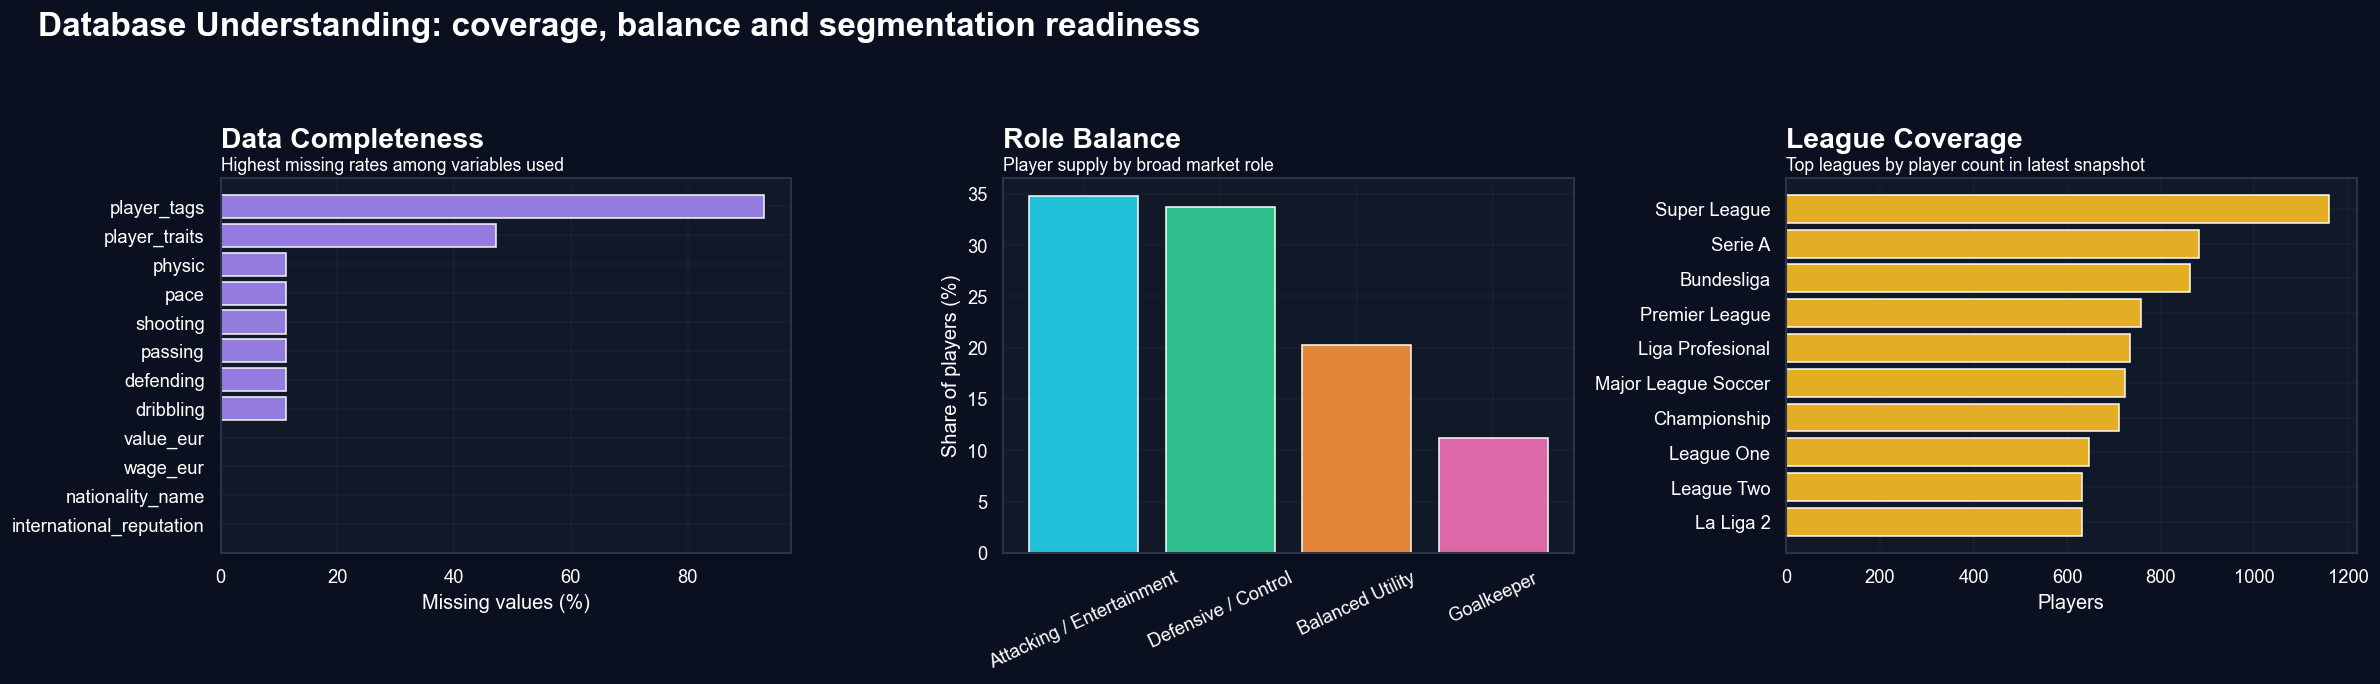

In [6]:
# Missingness + categorical balance: compact data understanding view.
fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))

missing = players_clean[focus_cols].isna().mean().sort_values(ascending=True).tail(12).mul(100)
axes[0].barh(missing.index, missing.values, color=PURPLE, alpha=0.88)
style_axis(axes[0], 'Data Completeness', 'Highest missing rates among variables used')
axes[0].set_xlabel('Missing values (%)')

role_counts = players_clean['role_group'].value_counts(normalize=True).mul(100)
axes[1].bar(role_counts.index, role_counts.values, color=[CYAN, GREEN, ORANGE, PINK], alpha=0.9)
style_axis(axes[1], 'Role Balance', 'Player supply by broad market role')
axes[1].set_ylabel('Share of players (%)')
axes[1].tick_params(axis='x', rotation=25)

league_counts = players_clean['league_name'].value_counts().head(10).sort_values()
axes[2].barh(league_counts.index, league_counts.values, color=GOLD, alpha=0.9)
style_axis(axes[2], 'League Coverage', 'Top leagues by player count in latest snapshot')
axes[2].set_xlabel('Players')

fig.suptitle('Database Understanding: coverage, balance and segmentation readiness', fontsize=20, fontweight='bold', x=0.02, ha='left')
plt.tight_layout(rect=[0, 0, 1, 0.92])
savefig('01_data_understanding_dashboard.png')
plt.show()


Saved: charts/02_price_skewness.png


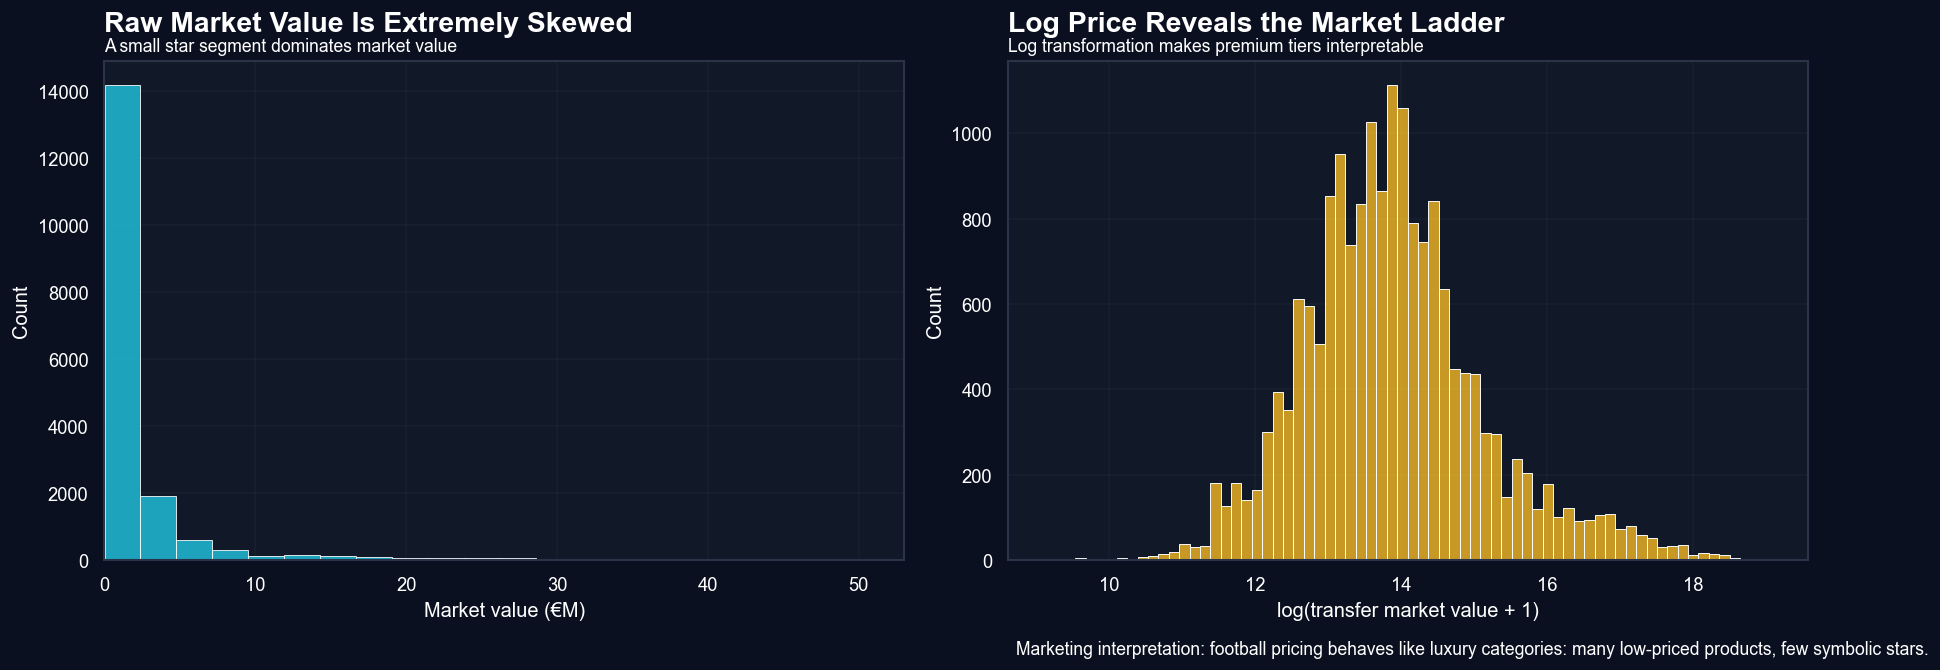

,value_eur,value_million,log_value_eur
count,1.803100e+04,18031.00,18031.00
mean,2.887096e+06,2.89,13.88
std,7.647092e+06,7.65,1.24
min,9.000000e+03,0.01,9.11
50%,1.000000e+06,1.00,13.82
75%,2.000000e+06,2.00,14.51
90%,5.000000e+06,5.00,15.42
95%,1.200000e+07,12.00,16.30
99%,3.750000e+07,37.50,17.44
max,1.905000e+08,190.50,19.07


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.8))

sns.histplot(players_clean['value_million'], bins=80, color=CYAN, alpha=0.75, ax=axes[0])
style_axis(axes[0], 'Raw Market Value Is Extremely Skewed', 'A small star segment dominates market value')
axes[0].set_xlabel('Market value (€M)')
axes[0].set_xlim(0, players_clean['value_million'].quantile(0.995))

sns.histplot(players_clean['log_value_eur'], bins=70, color=GOLD, alpha=0.78, ax=axes[1])
style_axis(axes[1], 'Log Price Reveals the Market Ladder', 'Log transformation makes premium tiers interpretable')
axes[1].set_xlabel('log(transfer market value + 1)')

add_slide_caption(axes[1], 'Marketing interpretation: football pricing behaves like luxury categories: many low-priced products, few symbolic stars.')
plt.tight_layout()
savefig('02_price_skewness.png')
plt.show()

players_clean[['value_eur', 'value_million', 'log_value_eur']].describe(percentiles=[.5, .75, .9, .95, .99]).round(2)


### Data Understanding Interpretation

The market is heavily right-skewed: most players sit in the mass market, while a small elite segment captures disproportionate value. That pattern supports a marketing interpretation: **clubs pay premiums for scarce positioning, not just average performance.**

> **Slide takeaway:** Transfer pricing looks less like a normal labor market and more like a premium brand market.


## 2. Visual Analytics: Three Marketing Positioning Dimensions

The following visuals are designed as slide-ready marketing analytics charts. Each chart answers one question:

- Does the market reward **future upside**?
- Do leagues behave like **brand containers**?
- Are attacking players priced as **attention assets**?


Saved: charts/03_youth_growth_positioning.png


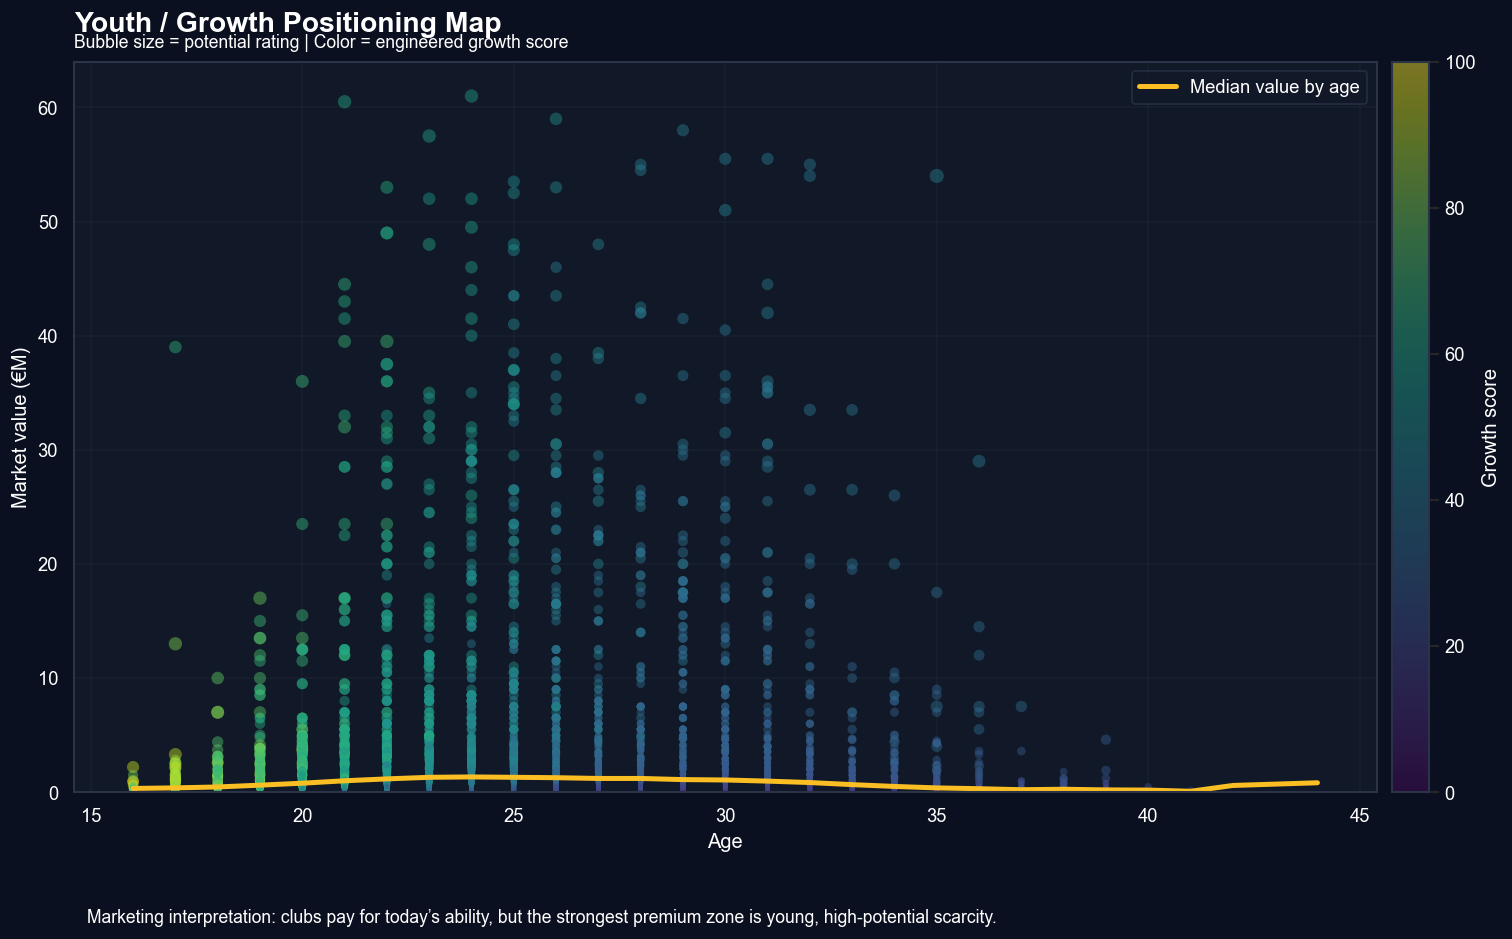

In [8]:
# A. Youth / Growth Positioning: age vs price with potential bubble.
plot_df = players_clean.dropna(subset=['age', 'value_million', 'potential', 'attention_score']).copy()
plot_df = plot_df.sample(min(9000, len(plot_df)), random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(13.8, 8))
sc = ax.scatter(
    plot_df['age'], plot_df['value_million'],
    s=np.clip((plot_df['potential'] - 55) ** 2 / 18, 8, 260),
    c=plot_df['growth_score'], cmap='viridis', alpha=0.45, linewidths=0
)

# Smooth median line by age.
age_line = players_clean.groupby('age')['value_million'].median().rolling(3, center=True, min_periods=1).mean()
ax.plot(age_line.index, age_line.values, color=GOLD, linewidth=3, label='Median value by age')

# Label top young stars.
top_young = players_clean[players_clean['age'].le(23)].nlargest(8, 'value_million')
for _, r in top_young.iterrows():
    ax.annotate(r['short_name'], (r['age'], r['value_million']), xytext=(5, 5), textcoords='offset points', fontsize=8.5, color=TEXT)

style_axis(ax, 'Youth / Growth Positioning Map', 'Bubble size = potential rating | Color = engineered growth score')
ax.set_xlabel('Age')
ax.set_ylabel('Market value (€M)')
ax.set_ylim(0, players_clean['value_million'].quantile(0.997))
ax.legend(loc='upper right')
cbar = fig.colorbar(sc, ax=ax, pad=0.01)
cbar.set_label('Growth score', color=TEXT)
add_slide_caption(ax, 'Marketing interpretation: clubs pay for today’s ability, but the strongest premium zone is young, high-potential scarcity.')
plt.tight_layout()
savefig('03_youth_growth_positioning.png')
plt.show()


Saved: charts/04_league_brand_ladder.png


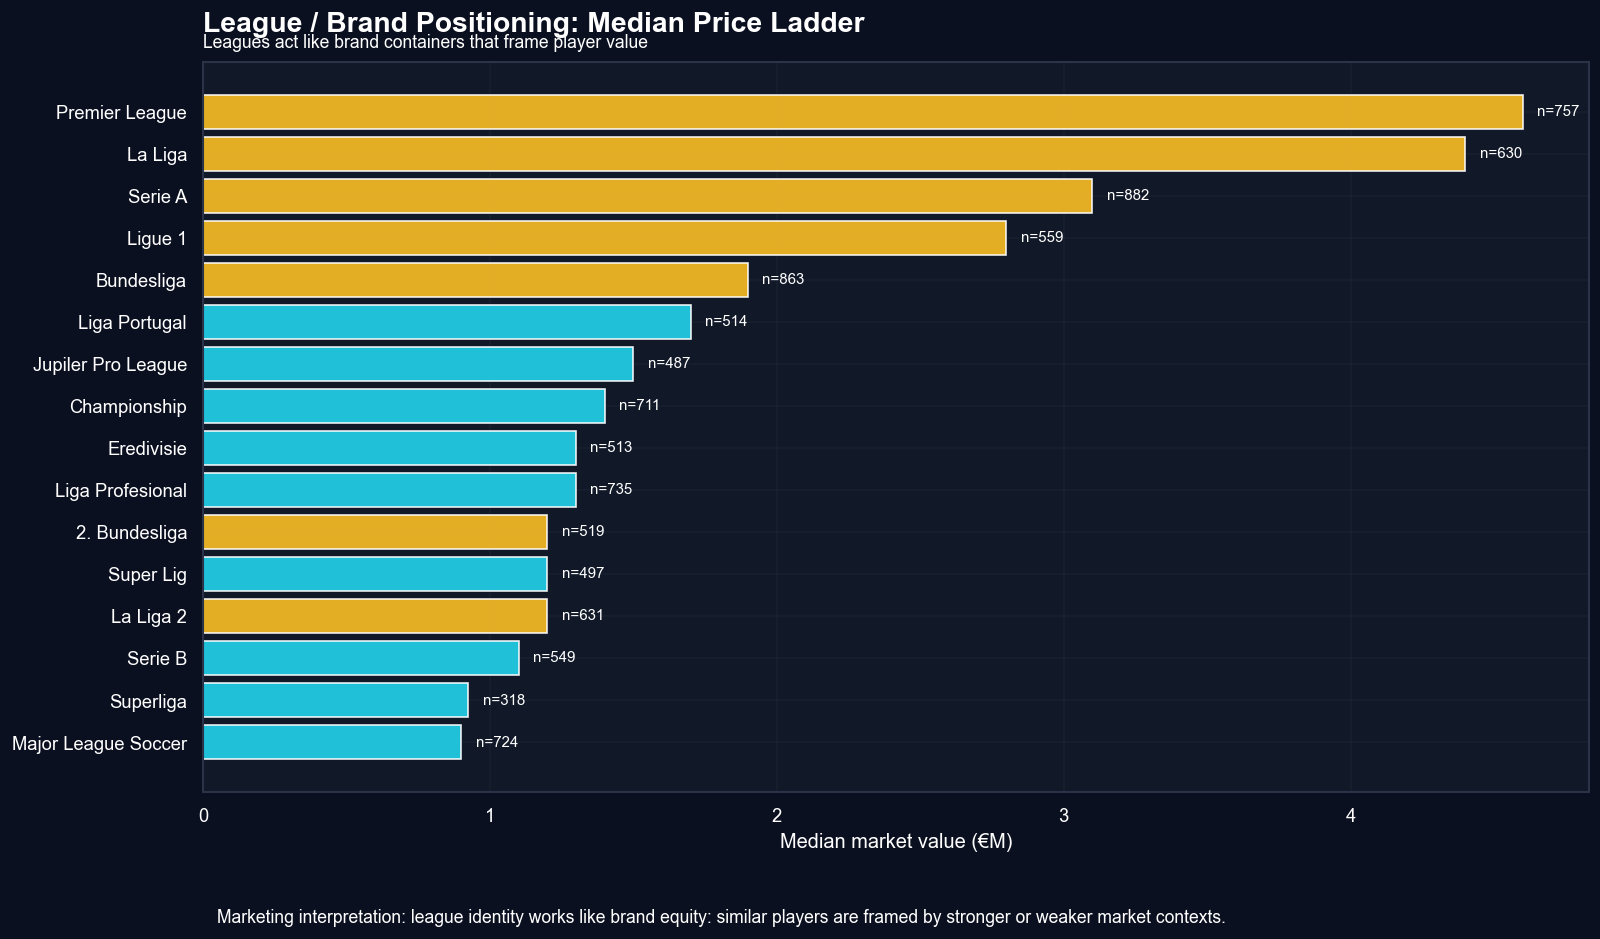

,players,median_value,mean_value,avg_overall,avg_brand,top_share
league_name,,,,,,
Premier League,757,4.60,12.47,72.68,61.99,1.0
La Liga,630,4.40,10.65,72.90,58.01,1.0
Serie A,882,3.10,7.84,72.51,56.96,1.0
Ligue 1,559,2.80,6.75,70.87,48.77,1.0
Bundesliga,863,1.90,6.44,69.20,56.39,1.0
Liga Portugal,514,1.70,3.93,68.94,32.69,0.0
Jupiler Pro League,487,1.50,2.13,67.16,39.70,0.0
Championship,711,1.40,1.74,66.49,23.91,0.0
Eredivisie,513,1.30,2.96,66.64,32.84,0.0


In [9]:
# B. League / Brand Positioning: price ladder across leagues.
league_summary = (
    players_clean.groupby('league_name', observed=True)
    .agg(players=('short_name', 'count'), median_value=('value_million', 'median'), mean_value=('value_million', 'mean'),
         avg_overall=('overall', 'mean'), avg_brand=('club_brand_score', 'mean'), top_share=('top_league', 'mean'))
    .query('players >= 150')
    .sort_values('median_value', ascending=False)
    .head(16)
)

fig, ax = plt.subplots(figsize=(13.5, 8))
colors = np.where(league_summary['top_share'].gt(0.5), GOLD, CYAN)
ax.barh(league_summary.index[::-1], league_summary['median_value'][::-1], color=colors[::-1], alpha=0.9)
style_axis(ax, 'League / Brand Positioning: Median Price Ladder', 'Leagues act like brand containers that frame player value')
ax.set_xlabel('Median market value (€M)')
for i, (league, row) in enumerate(league_summary.iloc[::-1].iterrows()):
    ax.text(row['median_value'] + 0.05, i, f"n={int(row['players'])}", va='center', color=MUTED, fontsize=9)
add_slide_caption(ax, 'Marketing interpretation: league identity works like brand equity: similar players are framed by stronger or weaker market contexts.')
plt.tight_layout()
savefig('04_league_brand_ladder.png')
plt.show()

league_summary.round(2)


Saved: charts/05_attention_positioning.png


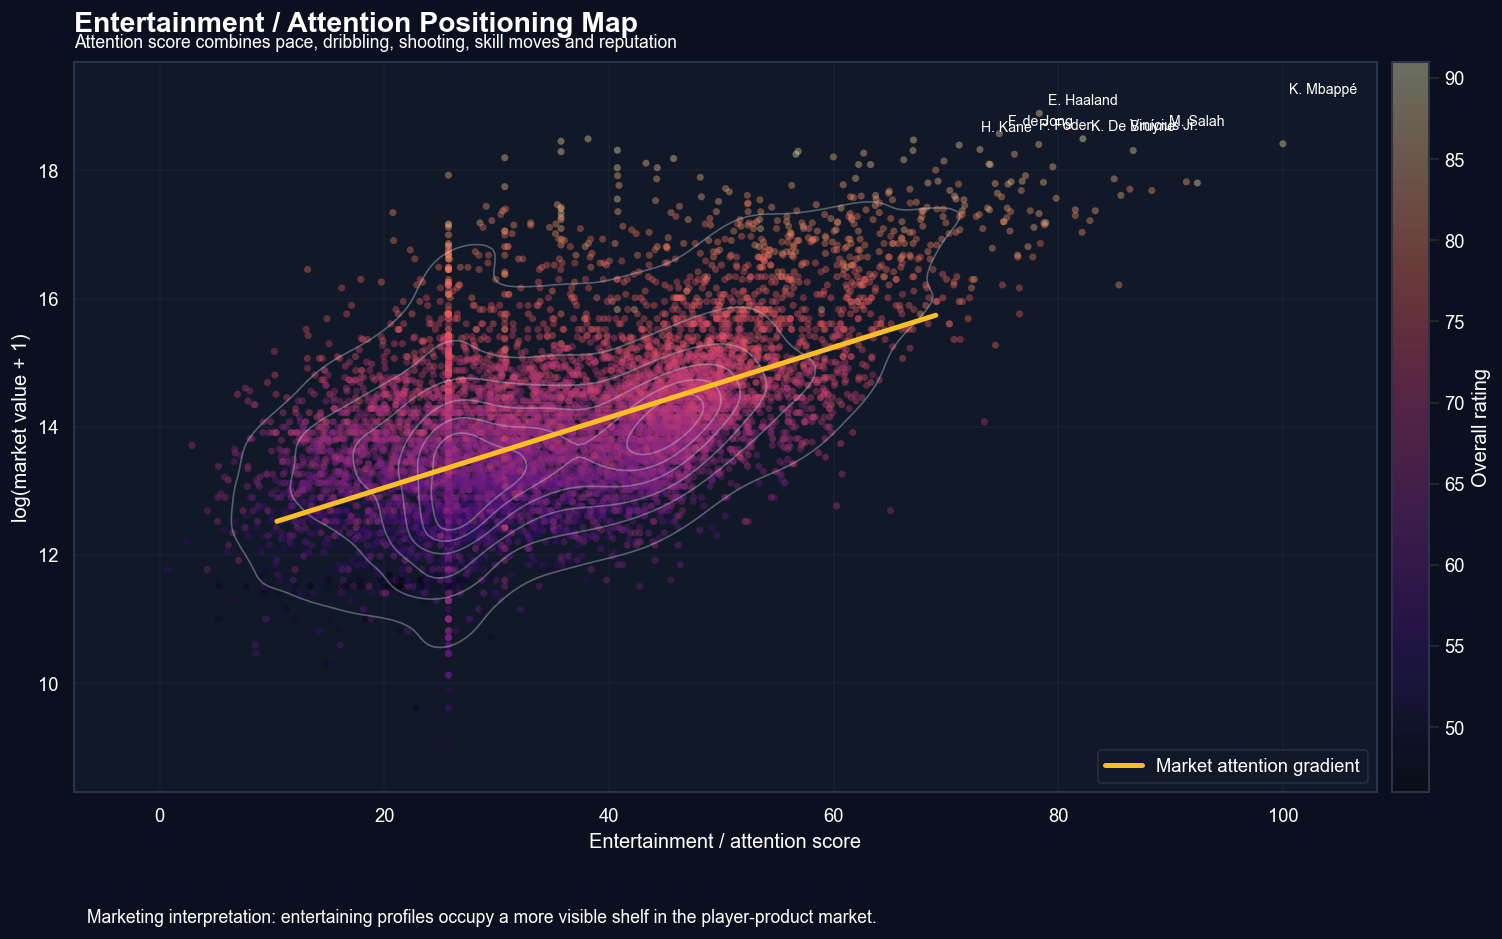

In [10]:
# C. Entertainment / Attention Positioning: entertainment proxy vs fee.
plot_df = players_clean.dropna(subset=['attention_score', 'value_million', 'overall']).copy()
plot_df = plot_df.sample(min(10000, len(plot_df)), random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(13.8, 8))
sns.kdeplot(
    data=plot_df, x='attention_score', y='log_value_eur',
    levels=7, color='#CBD5E1', linewidths=1, alpha=0.38, ax=ax
)
sc = ax.scatter(
    plot_df['attention_score'], plot_df['log_value_eur'],
    c=plot_df['overall'], cmap='magma', s=18, alpha=0.38, linewidths=0
)

# Regression guide line for story, not formal inference.
x = plot_df['attention_score'].astype(float).values
y = plot_df['log_value_eur'].astype(float).values
coef = np.polyfit(x, y, 1)
xx = np.linspace(np.nanpercentile(x, 1), np.nanpercentile(x, 99), 100)
ax.plot(xx, coef[0] * xx + coef[1], color=GOLD, linewidth=3, label='Market attention gradient')

# Highlight elite entertainers.
elite_att = players_clean[players_clean['attention_score'].ge(players_clean['attention_score'].quantile(.985))].nlargest(8, 'value_million')
for _, r in elite_att.iterrows():
    ax.annotate(r['short_name'], (r['attention_score'], r['log_value_eur']), xytext=(5, 5), textcoords='offset points', fontsize=8.5, color=TEXT)

style_axis(ax, 'Entertainment / Attention Positioning Map', 'Attention score combines pace, dribbling, shooting, skill moves and reputation')
ax.set_xlabel('Entertainment / attention score')
ax.set_ylabel('log(market value + 1)')
ax.legend(loc='lower right')
cbar = fig.colorbar(sc, ax=ax, pad=0.01)
cbar.set_label('Overall rating', color=TEXT)
add_slide_caption(ax, 'Marketing interpretation: entertaining profiles occupy a more visible shelf in the player-product market.')
plt.tight_layout()
savefig('05_attention_positioning.png')
plt.show()


### Visual Analytics Interpretation

The three maps show that clubs reveal preference through spending in different ways:

- **Growth premium**: young players with high potential create option value.
- **Brand premium**: league context raises perceived quality and resale confidence.
- **Attention premium**: high-visibility attacking profiles receive stronger market attention.

> **Slide takeaway:** The transfer market is a positioning market: clubs buy upside, brand context and attention.


## 3A. PCA: Latent Player Archetypes

PCA is used here as a storytelling tool, not a formal proof. The goal is to compress many player attributes into a small number of interpretable dimensions and reveal latent player archetypes.

> **Slide takeaway:** Player products cluster around recognizable archetypes, and price gradients appear across those archetypes.


In [11]:
attribute_cols = [
    'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic',
    'attacking_finishing', 'skill_ball_control', 'movement_acceleration',
    'movement_sprint_speed', 'movement_reactions', 'power_strength',
    'mentality_vision', 'mentality_composure', 'defending_standing_tackle',
    'defending_marking_awareness'
]
attribute_cols = [c for c in attribute_cols if c in players_clean.columns]

pca_base = players_clean.dropna(subset=['value_million', 'position_category', 'league_name']).copy()
X_raw = pca_base[attribute_cols].apply(pd.to_numeric, errors='coerce')
X_raw = X_raw.fillna(X_raw.median())

# Standardize and run PCA via SVD to avoid requiring sklearn.
X = (X_raw - X_raw.mean()) / X_raw.std(ddof=0).replace(0, 1)
U, S, Vt = np.linalg.svd(X.values, full_matrices=False)
components = U[:, :4] * S[:4]
explained = (S ** 2) / np.sum(S ** 2)

pca_base['PC1'] = components[:, 0]
pca_base['PC2'] = components[:, 1]
pca_base['PC3'] = components[:, 2]
pca_base['PC4'] = components[:, 3]

loadings = pd.DataFrame(Vt[:4].T, index=attribute_cols, columns=['PC1', 'PC2', 'PC3', 'PC4'])
print('Explained variance:', [f'{v:.1%}' for v in explained[:4]])
loadings.sort_values('PC1', ascending=False).round(3)


Explained variance: ['38.5%', '24.4%', '14.1%', '8.0%']


,PC1,PC2,PC3,PC4
defending,0.023,0.430,-0.082,-0.381
power_strength,-0.035,0.330,-0.124,0.594
physic,-0.049,0.356,-0.239,0.360
defending_standing_tackle,-0.123,0.413,0.244,-0.217
defending_marking_awareness,-0.134,0.418,0.228,-0.184
pace,-0.168,-0.255,0.164,-0.086
shooting,-0.256,-0.231,-0.351,0.120
movement_reactions,-0.269,0.178,-0.245,0.021
movement_sprint_speed,-0.272,-0.074,0.424,0.122
movement_acceleration,-0.281,-0.102,0.415,0.047


In [12]:
def describe_pc(loadings, pc):
    s = loadings[pc].sort_values()
    negative = ', '.join(s.head(4).index)
    positive = ', '.join(s.tail(4).index[::-1])
    return pd.Series({'negative_side': negative, 'positive_side': positive})

pc_story = pd.concat([describe_pc(loadings, pc) for pc in ['PC1', 'PC2', 'PC3']], axis=1)
pc_story.columns = ['PC1', 'PC2', 'PC3']
pc_story


,PC1,PC2,PC3
negative_side,"skill_ball_control, mentality_vision, mentalit...","pace, shooting, dribbling, attacking_finishing","shooting, passing, dribbling, movement_reactions"
positive_side,"defending, power_strength, physic, defending_s...","defending, defending_marking_awareness, defend...","movement_sprint_speed, movement_acceleration, ..."


Saved: charts/06_pca_price_gradient.png


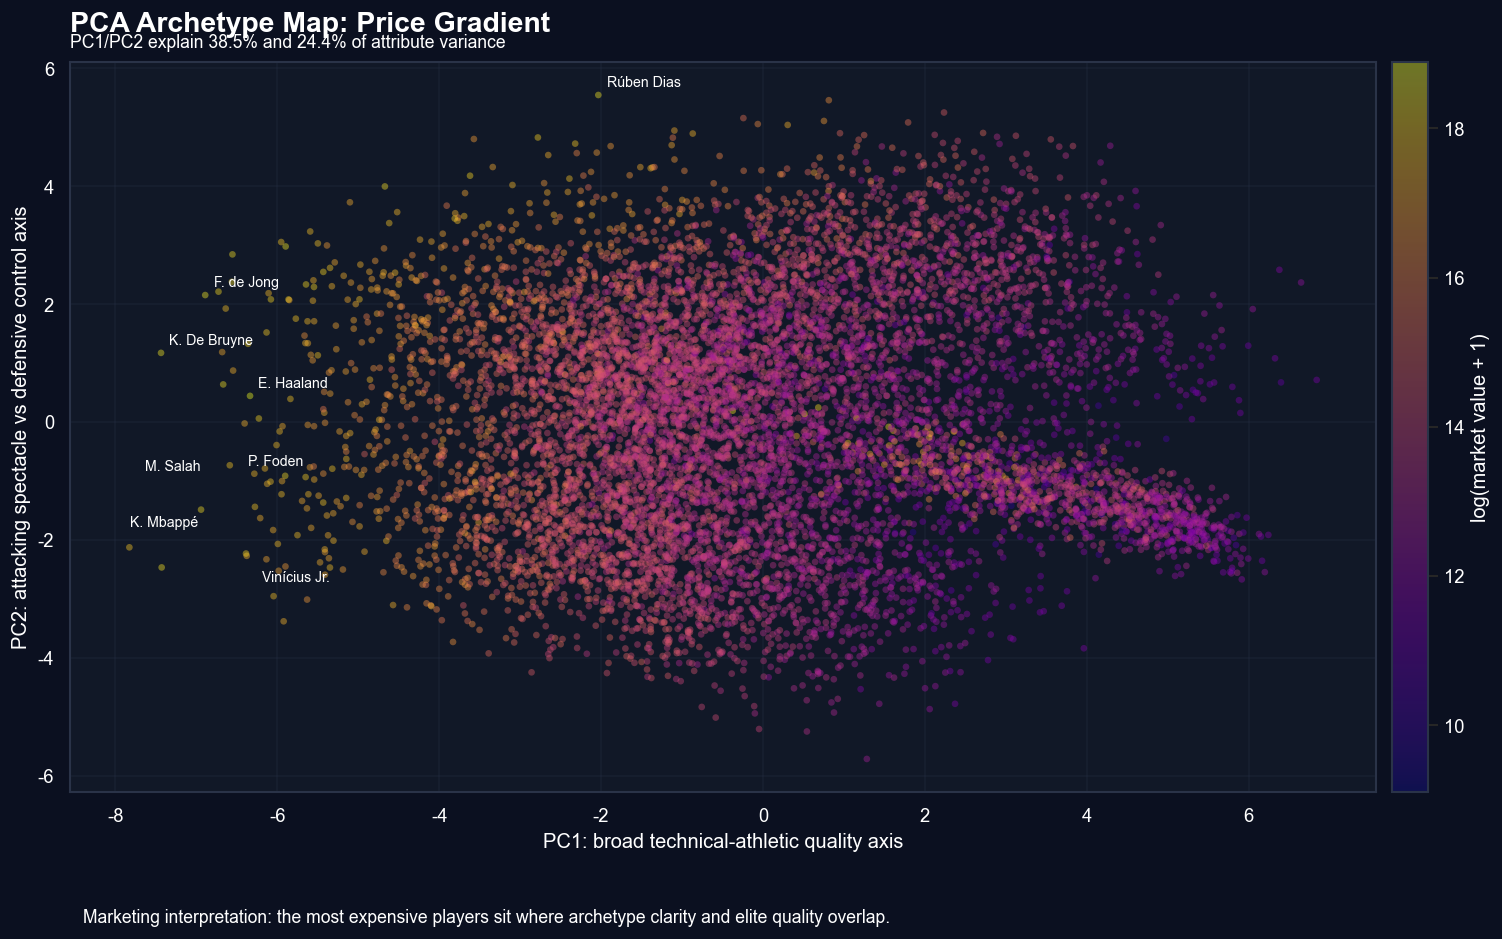

In [13]:
# PCA scatter: price gradient over archetype map.
p = pca_base.sample(min(9000, len(pca_base)), random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(13.8, 8))
sc = ax.scatter(p['PC1'], p['PC2'], c=p['log_value_eur'], cmap='plasma', s=16, alpha=0.42, linewidths=0)

for _, r in pca_base.nlargest(8, 'value_million').iterrows():
    ax.annotate(r['short_name'], (r['PC1'], r['PC2']), xytext=(5, 5), textcoords='offset points', fontsize=8.5, color=TEXT)

style_axis(ax, 'PCA Archetype Map: Price Gradient', f'PC1/PC2 explain {explained[0]:.1%} and {explained[1]:.1%} of attribute variance')
ax.set_xlabel('PC1: broad technical-athletic quality axis')
ax.set_ylabel('PC2: attacking spectacle vs defensive control axis')
cbar = fig.colorbar(sc, ax=ax, pad=0.01)
cbar.set_label('log(market value + 1)', color=TEXT)
add_slide_caption(ax, 'Marketing interpretation: the most expensive players sit where archetype clarity and elite quality overlap.')
plt.tight_layout()
savefig('06_pca_price_gradient.png')
plt.show()


Saved: charts/07_pca_position_league.png


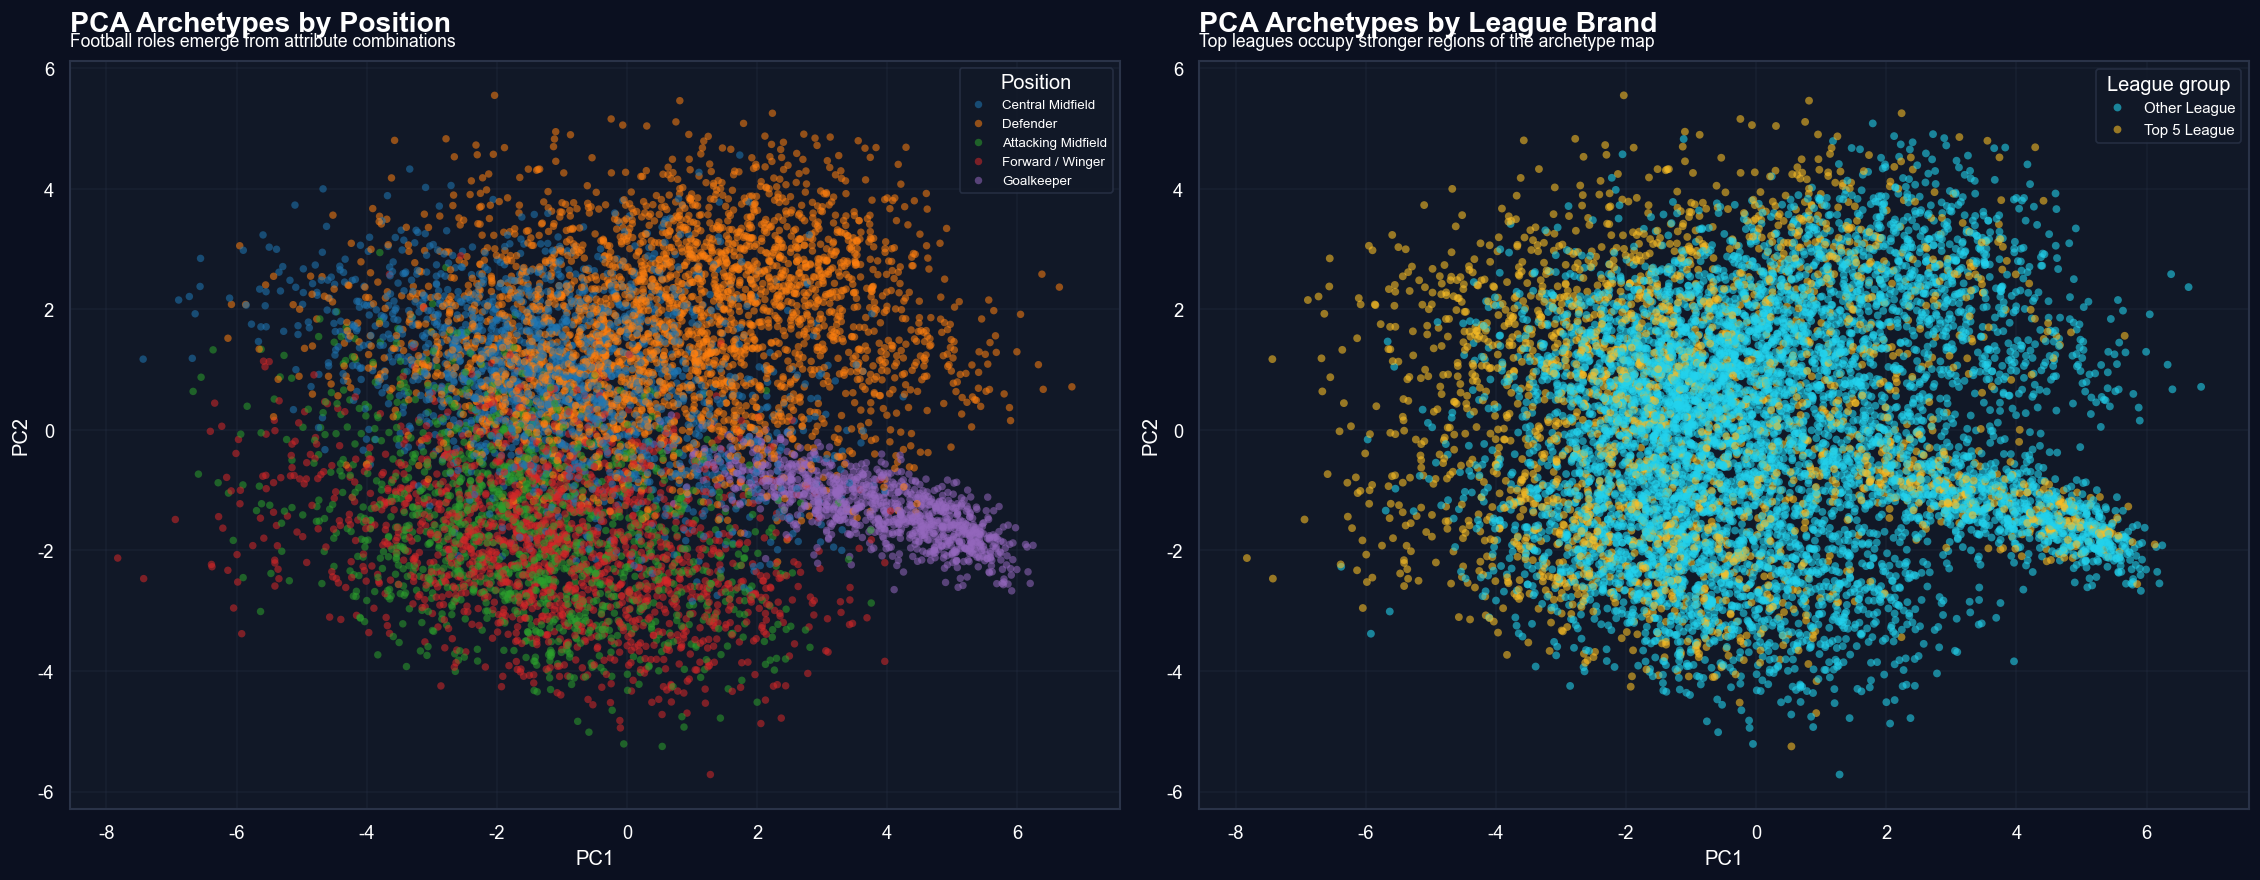

In [14]:
# PCA scatter by role and league brand.
fig, axes = plt.subplots(1, 2, figsize=(19, 7.5))

sns.scatterplot(data=p, x='PC1', y='PC2', hue='position_category', s=20, alpha=0.55, linewidth=0, ax=axes[0], palette='tab10')
style_axis(axes[0], 'PCA Archetypes by Position', 'Football roles emerge from attribute combinations')
axes[0].legend(loc='best', fontsize=8, title='Position')

sns.scatterplot(data=p, x='PC1', y='PC2', hue='top_league_label', s=22, alpha=0.58, linewidth=0, ax=axes[1], palette=[CYAN, GOLD])
style_axis(axes[1], 'PCA Archetypes by League Brand', 'Top leagues occupy stronger regions of the archetype map')
axes[1].legend(loc='best', fontsize=9, title='League group')

plt.tight_layout()
savefig('07_pca_position_league.png')
plt.show()


### PCA Marketing Interpretation

PCA turns detailed player attributes into a marketable archetype map. In marketing language:

- **PC1** behaves like a broad quality-and-readiness axis.
- **PC2** separates attacking spectacle from defensive control.
- High-priced players are not randomly distributed; they concentrate in archetype regions that combine quality, visibility and scarce role fit.

> **Slide takeaway:** Clubs pay more when a player’s archetype is both clear and commercially valuable.


## 3B. t-SNE: How the Market Organizes Player Identities

The t-SNE section visualizes local similarity among player profiles. It asks: **when players are grouped by identity rather than by table columns, where do price and brand premiums appear?**

Parameter choices:
- sample size is capped for readability and speed;
- perplexity is scaled to sample size;
- PCA initialization improves stability.

> **Slide takeaway:** The market organizes players into identity neighborhoods, then assigns premiums to selected neighborhoods.


In [15]:
tsne_cols = attribute_cols + ['age', 'overall', 'potential', 'potential_gap', 'attention_score', 'growth_score']
tsne_base = players_clean.dropna(subset=['value_million', 'age_group', 'role_group']).copy()
tsne_base = tsne_base.sample(min(2600, len(tsne_base)), random_state=RANDOM_STATE).reset_index(drop=True)
X_tsne_raw = tsne_base[tsne_cols].apply(pd.to_numeric, errors='coerce')
X_tsne_raw = X_tsne_raw.fillna(X_tsne_raw.median())
X_tsne = (X_tsne_raw - X_tsne_raw.mean()) / X_tsne_raw.std(ddof=0).replace(0, 1)

if SKLEARN_AVAILABLE:
    perplexity = int(np.clip(len(tsne_base) / 80, 18, 40))
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        learning_rate='auto',
        init='pca',
        random_state=RANDOM_STATE,
        max_iter=900
    )
    emb = tsne.fit_transform(X_tsne.values)
    tsne_base['TSNE1'] = emb[:, 0]
    tsne_base['TSNE2'] = emb[:, 1]
    print(f't-SNE completed | sample={len(tsne_base):,} | perplexity={perplexity}')
else:
    # Fallback keeps the notebook runnable; install scikit-learn for true t-SNE.
    U2, S2, Vt2 = np.linalg.svd(X_tsne.values, full_matrices=False)
    tsne_base['TSNE1'] = U2[:, 0] * S2[0]
    tsne_base['TSNE2'] = U2[:, 1] * S2[1]
    print('scikit-learn is not installed. Displaying PCA fallback embedding. Install scikit-learn to run true t-SNE.')


t-SNE completed | sample=2,600 | perplexity=32


Saved: charts/08_tsne_identity_maps.png


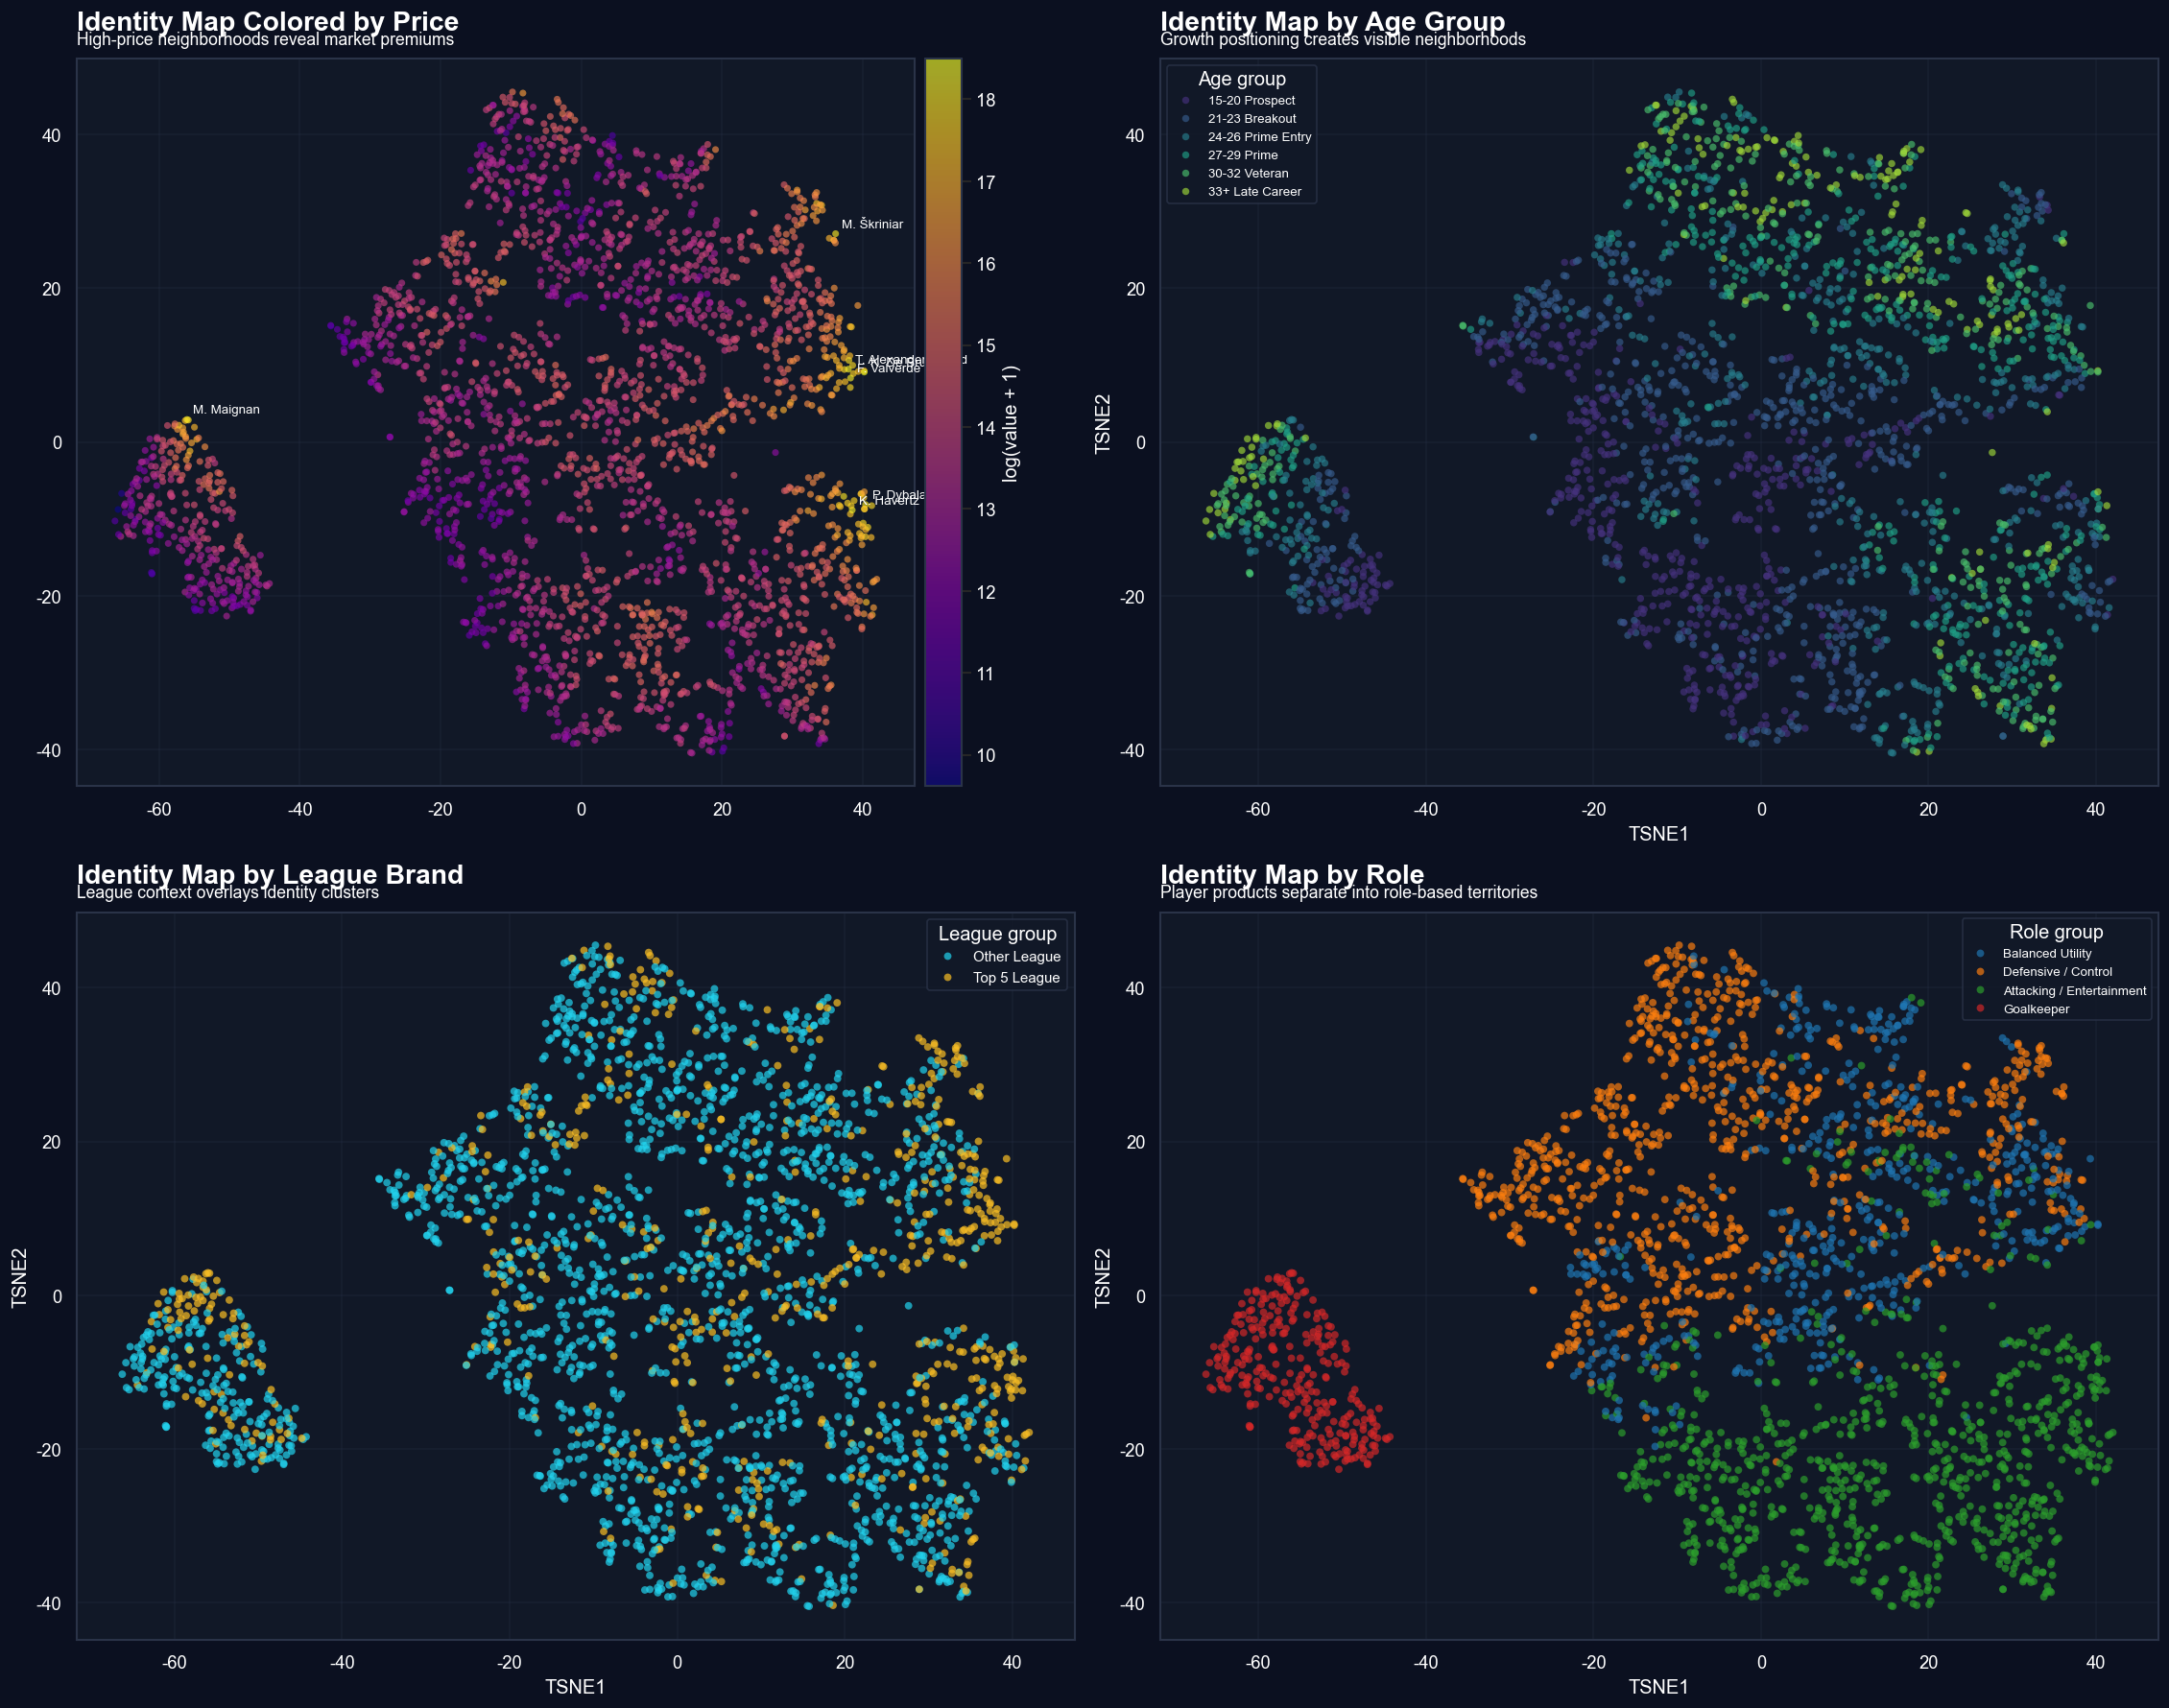

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(19, 15))

# 1 fee gradient
sc = axes[0, 0].scatter(tsne_base['TSNE1'], tsne_base['TSNE2'], c=tsne_base['log_value_eur'], cmap='plasma', s=18, alpha=0.65, linewidths=0)
style_axis(axes[0, 0], 'Identity Map Colored by Price', 'High-price neighborhoods reveal market premiums')
fig.colorbar(sc, ax=axes[0, 0], pad=0.01, label='log(value + 1)')

# 2 age group
sns.scatterplot(data=tsne_base, x='TSNE1', y='TSNE2', hue='age_group', s=20, alpha=0.65, linewidth=0, ax=axes[0, 1], palette='viridis')
style_axis(axes[0, 1], 'Identity Map by Age Group', 'Growth positioning creates visible neighborhoods')
axes[0, 1].legend(fontsize=8, title='Age group')

# 3 league group
sns.scatterplot(data=tsne_base, x='TSNE1', y='TSNE2', hue='top_league_label', s=22, alpha=0.7, linewidth=0, ax=axes[1, 0], palette=[CYAN, GOLD])
style_axis(axes[1, 0], 'Identity Map by League Brand', 'League context overlays identity clusters')
axes[1, 0].legend(fontsize=9, title='League group')

# 4 role group
sns.scatterplot(data=tsne_base, x='TSNE1', y='TSNE2', hue='role_group', s=22, alpha=0.68, linewidth=0, ax=axes[1, 1], palette='tab10')
style_axis(axes[1, 1], 'Identity Map by Role', 'Player products separate into role-based territories')
axes[1, 1].legend(fontsize=8, title='Role group')

# Highlight expensive players and young talents on first chart.
for _, r in tsne_base.nlargest(7, 'value_million').iterrows():
    axes[0, 0].annotate(r['short_name'], (r['TSNE1'], r['TSNE2']), xytext=(4, 4), textcoords='offset points', fontsize=8, color=TEXT)

plt.tight_layout()
savefig('08_tsne_identity_maps.png')
plt.show()


### t-SNE Marketing Interpretation

The identity map helps reposition the dataset from “rows of players” to “market neighborhoods.” Expensive players often sit in neighborhoods associated with clear attacking or elite all-round identities, while young prospects create a separate growth-oriented premium zone.

> **Slide takeaway:** The market does not price isolated attributes; it prices recognizable player identities.


## 3C. Marketing Positioning Maps

These maps translate analysis into consulting-style slides. They are designed to be easy to explain in a 10-minute presentation.


Saved: charts/09_positioning_maps.png


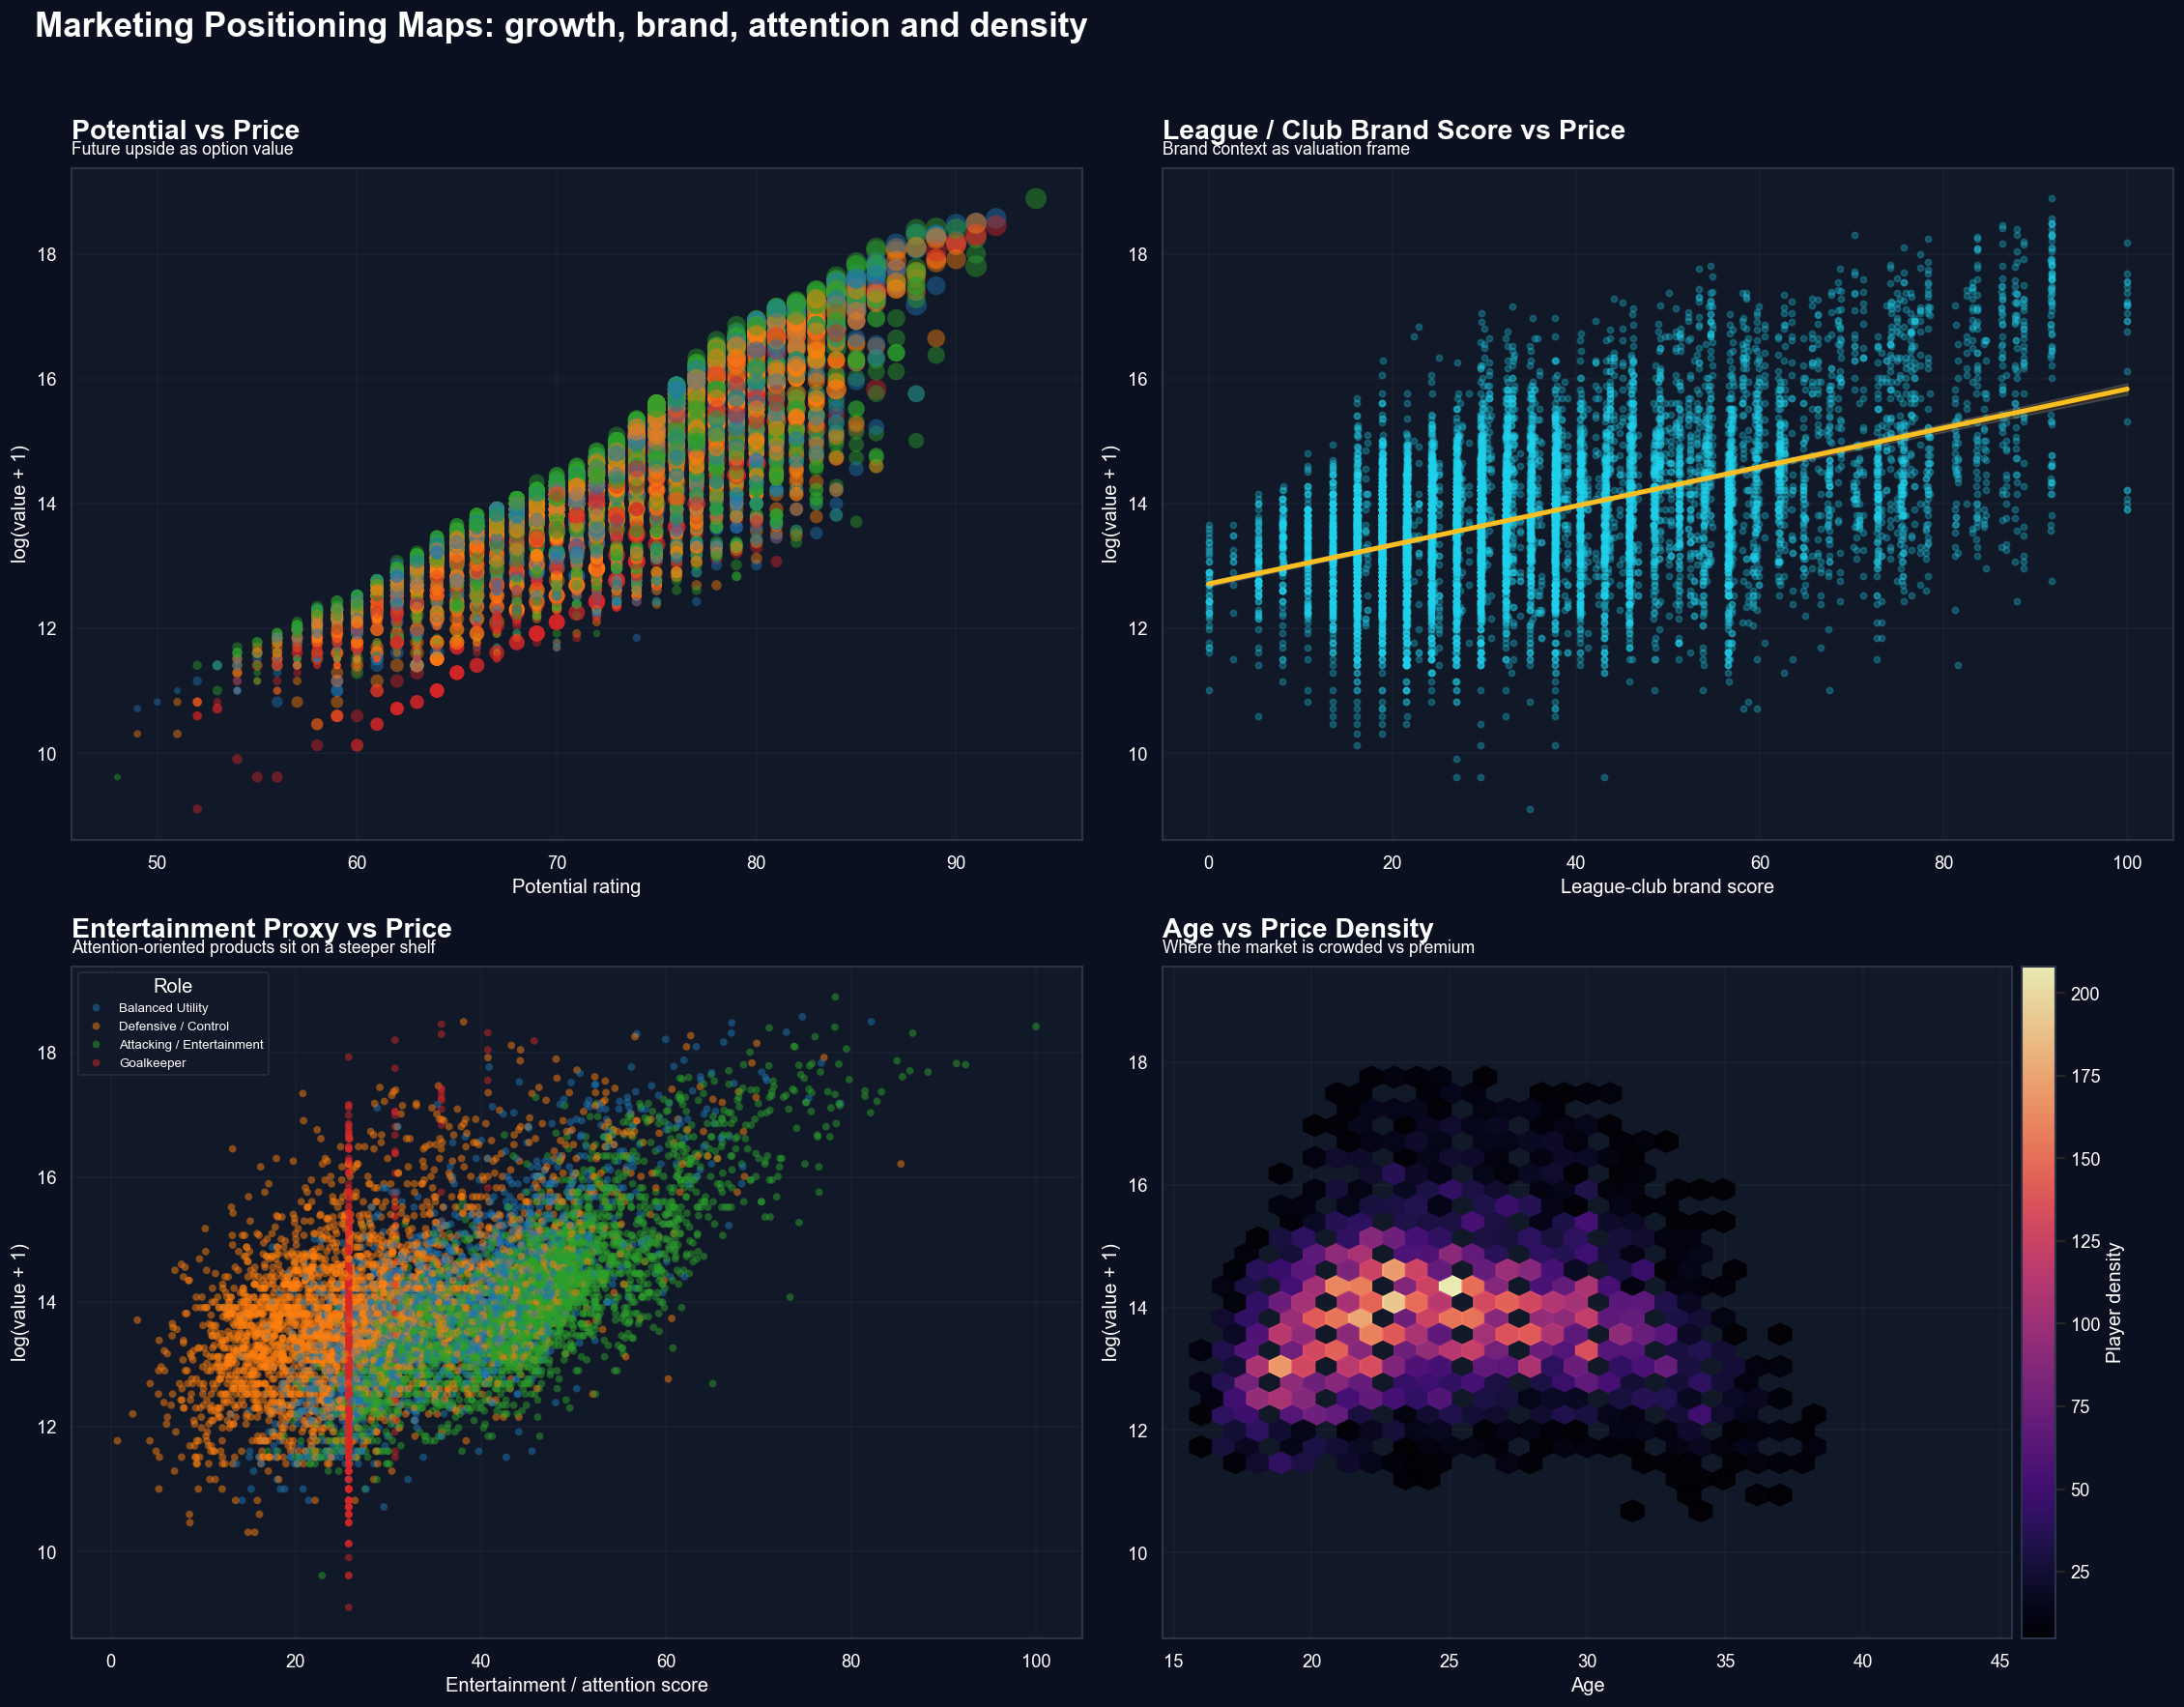

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(19, 15))

# Potential vs fee
sns.scatterplot(
    data=plot_df, x='potential', y='log_value_eur', hue='role_group', size='overall',
    sizes=(10, 180), alpha=0.45, linewidth=0, ax=axes[0, 0], palette='tab10', legend=False
)
style_axis(axes[0, 0], 'Potential vs Price', 'Future upside as option value')
axes[0, 0].set_xlabel('Potential rating')
axes[0, 0].set_ylabel('log(value + 1)')

# Brand score vs fee
sns.regplot(
    data=plot_df.dropna(subset=['club_brand_score']), x='club_brand_score', y='log_value_eur',
    scatter_kws={'s': 14, 'alpha': 0.28, 'color': CYAN}, line_kws={'color': GOLD, 'linewidth': 3}, ax=axes[0, 1]
)
style_axis(axes[0, 1], 'League / Club Brand Score vs Price', 'Brand context as valuation frame')
axes[0, 1].set_xlabel('League-club brand score')
axes[0, 1].set_ylabel('log(value + 1)')

# Entertainment proxy vs fee by attacking/defensive role
sns.scatterplot(
    data=plot_df, x='attention_score', y='log_value_eur', hue='role_group',
    s=22, alpha=0.5, linewidth=0, ax=axes[1, 0], palette='tab10'
)
style_axis(axes[1, 0], 'Entertainment Proxy vs Price', 'Attention-oriented products sit on a steeper shelf')
axes[1, 0].set_xlabel('Entertainment / attention score')
axes[1, 0].set_ylabel('log(value + 1)')
axes[1, 0].legend(fontsize=8, title='Role')

# Hexbin: age vs fee density
hb = axes[1, 1].hexbin(
    players_clean['age'].astype(float), players_clean['log_value_eur'].astype(float),
    gridsize=34, cmap='magma', mincnt=5, alpha=0.92
)
style_axis(axes[1, 1], 'Age vs Price Density', 'Where the market is crowded vs premium')
axes[1, 1].set_xlabel('Age')
axes[1, 1].set_ylabel('log(value + 1)')
fig.colorbar(hb, ax=axes[1, 1], pad=0.01, label='Player density')

fig.suptitle('Marketing Positioning Maps: growth, brand, attention and density', fontsize=21, fontweight='bold', x=0.02, ha='left')
plt.tight_layout(rect=[0, 0, 1, 0.96])
savefig('09_positioning_maps.png')
plt.show()


### Positioning Map Interpretation

The maps reinforce the STP story: clubs segment the market by age, ability, identity and brand context; then they target and pay for profiles that offer growth, visibility or strategic fit.

> **Slide takeaway:** Player price is a positioning signal, not just a performance score.


## 3D. Segmentation Analysis: Market Segments and Positioning Categories

Clustering creates market-facing player segments. The goal is not to discover the “true” taxonomy of football; it is to name commercially meaningful player-product categories.

> **Slide takeaway:** Transfer spending reveals which market segments command premiums.


In [18]:
cluster_cols = [
    'age', 'overall', 'potential', 'potential_gap', 'attention_score', 'growth_score',
    'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic'
]
cluster_base = players_clean.dropna(subset=['value_million', 'role_group']).copy()
X_cluster_raw = cluster_base[cluster_cols].apply(pd.to_numeric, errors='coerce').fillna(cluster_base[cluster_cols].median(numeric_only=True))
X_cluster = (X_cluster_raw - X_cluster_raw.mean()) / X_cluster_raw.std(ddof=0).replace(0, 1)

n_clusters = 6
if SKLEARN_AVAILABLE:
    km = KMeans(n_clusters=n_clusters, random_state=RANDOM_STATE, n_init=20)
    cluster_base['cluster_id'] = km.fit_predict(X_cluster.values)
else:
    # Lightweight deterministic KMeans fallback.
    rng = np.random.default_rng(RANDOM_STATE)
    Xv = X_cluster.values
    centers = Xv[rng.choice(len(Xv), size=n_clusters, replace=False)]
    for _ in range(60):
        dist = ((Xv[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        labels = dist.argmin(axis=1)
        new_centers = np.vstack([Xv[labels == k].mean(axis=0) if np.any(labels == k) else centers[k] for k in range(n_clusters)])
        if np.allclose(centers, new_centers, atol=1e-4):
            break
        centers = new_centers
    cluster_base['cluster_id'] = labels

def name_cluster(row):
    if row['age'] <= 23.5 and row['potential_gap'] >= 5:
        return 'Young Growth Assets'
    if row['attention_score'] >= 70 and row['shooting'] >= 63:
        return 'Elite Entertainers'
    if row['defending'] >= 68 and row['physic'] >= 68:
        return 'Defensive Control Assets'
    if row['overall'] >= 75 and row['age'] >= 28:
        return 'Veteran Tactical Specialists'
    if row['passing'] >= 68 and row['dribbling'] >= 68:
        return 'Creative Connectors'
    return 'Value Utility Players'

cluster_profile_raw = cluster_base.groupby('cluster_id')[cluster_cols + ['value_million', 'top_league']].mean().round(2)
cluster_names = cluster_profile_raw.apply(name_cluster, axis=1).to_dict()
cluster_base['market_segment'] = cluster_base['cluster_id'].map(cluster_names)
players_clean = players_clean.merge(cluster_base[['short_name', 'club_name', 'league_name', 'cluster_id', 'market_segment']], on=['short_name', 'club_name', 'league_name'], how='left')

segment_profile = (
    cluster_base.groupby('market_segment')
    .agg(players=('short_name', 'count'), median_value=('value_million', 'median'), mean_value=('value_million', 'mean'),
         avg_age=('age', 'mean'), avg_overall=('overall', 'mean'), avg_potential=('potential', 'mean'),
         attention=('attention_score', 'mean'), growth=('growth_score', 'mean'), top_league_share=('top_league', 'mean'))
    .sort_values('median_value', ascending=False)
)
segment_profile.round(2)


,players,median_value,mean_value,avg_age,avg_overall,avg_potential,attention,growth,top_league_share
market_segment,,,,,,,,,
Creative Connectors,3065,4.5,10.56,27.15,74.82,76.76,52.94,38.13,0.54
Young Growth Assets,8134,0.9,1.66,21.13,62.48,72.25,31.59,52.96,0.25
Value Utility Players,6832,0.7,0.91,28.81,65.67,66.60,31.71,25.25,0.17


Saved: charts/10_segmentation_market_segments.png


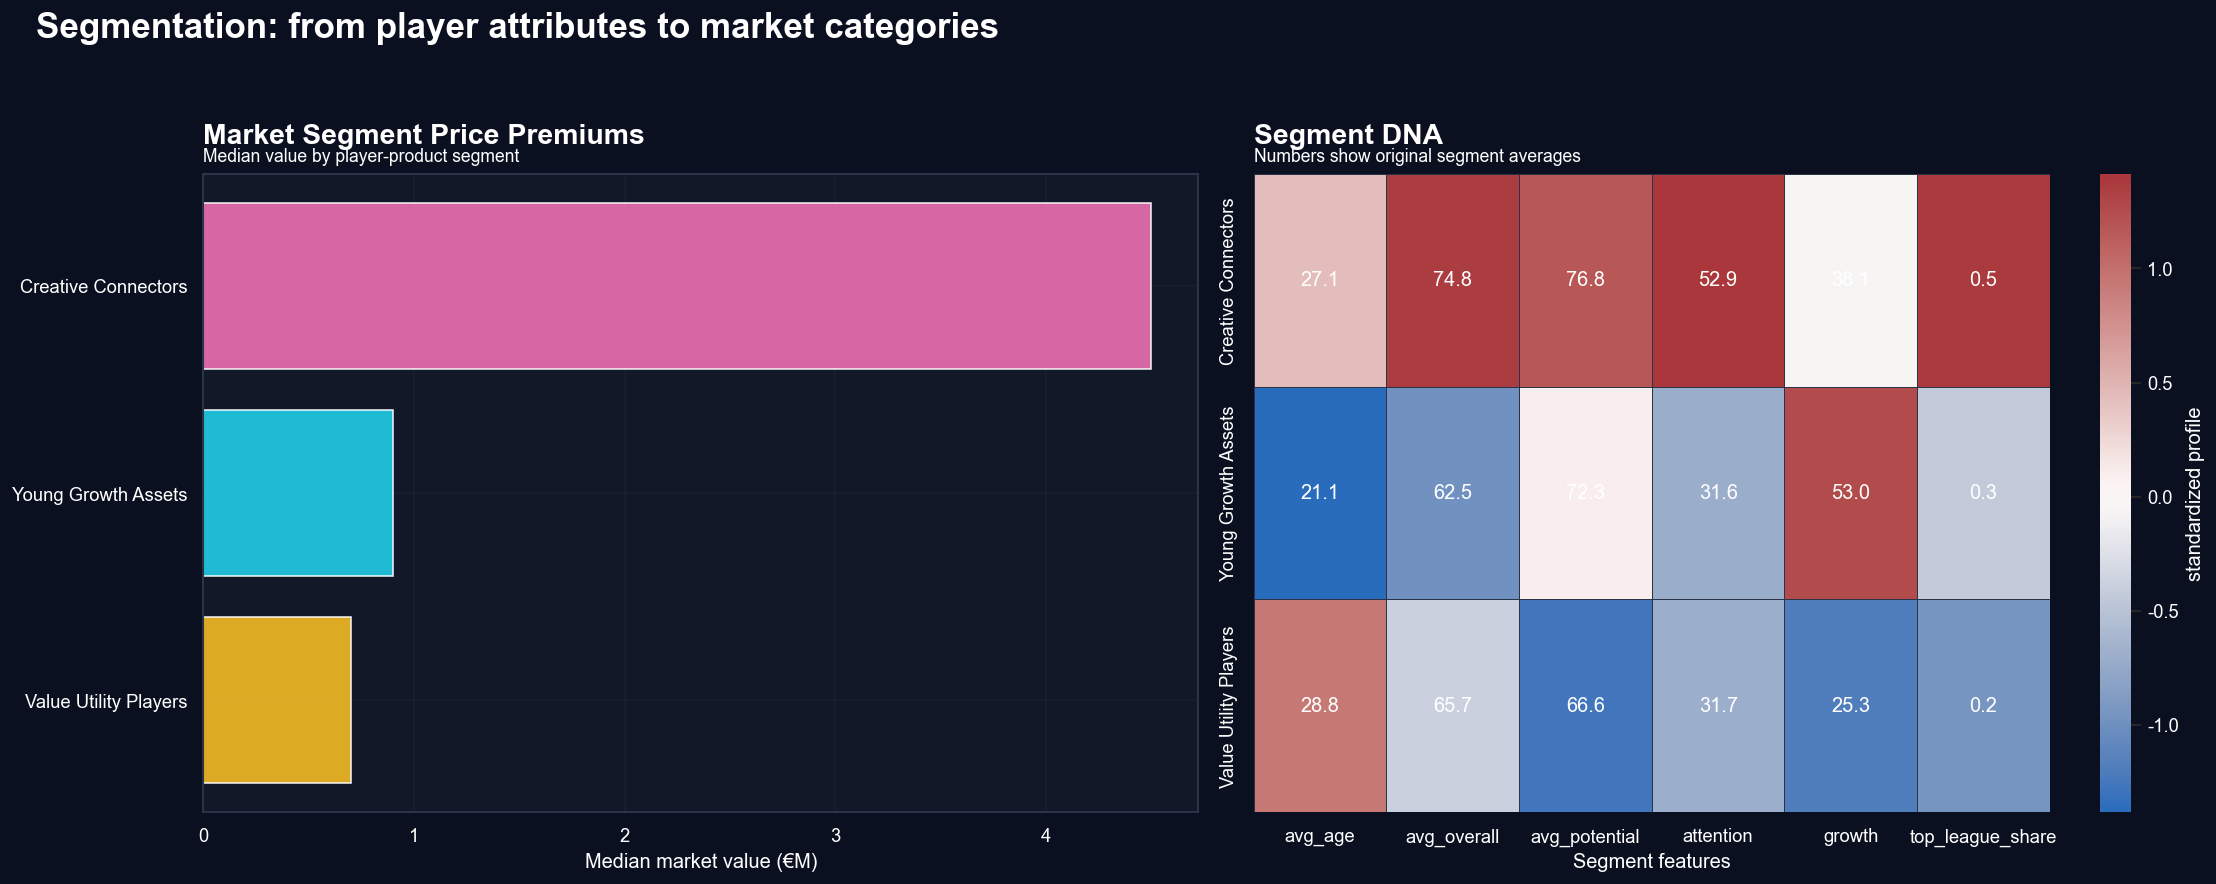

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(19, 7.5))

seg_order = segment_profile.sort_values('median_value', ascending=True).index
axes[0].barh(seg_order, segment_profile.loc[seg_order, 'median_value'], color=[GOLD, CYAN, PINK, GREEN, ORANGE, PURPLE][:len(seg_order)], alpha=0.88)
style_axis(axes[0], 'Market Segment Price Premiums', 'Median value by player-product segment')
axes[0].set_xlabel('Median market value (€M)')

heat_cols = ['avg_age', 'avg_overall', 'avg_potential', 'attention', 'growth', 'top_league_share']
heat = segment_profile[heat_cols].copy()
heat_z = (heat - heat.mean()) / heat.std(ddof=0).replace(0, 1)
sns.heatmap(heat_z, cmap='vlag', center=0, annot=heat.round(1), fmt='', linewidths=.6, linecolor=GRID, ax=axes[1], cbar_kws={'label': 'standardized profile'})
style_axis(axes[1], 'Segment DNA', 'Numbers show original segment averages')
axes[1].set_xlabel('Segment features')
axes[1].set_ylabel('')

fig.suptitle('Segmentation: from player attributes to market categories', fontsize=21, fontweight='bold', x=0.02, ha='left')
plt.tight_layout(rect=[0, 0, 1, 0.94])
savefig('10_segmentation_market_segments.png')
plt.show()


### Segmentation Marketing Interpretation

The segmentation reframes the database as a product portfolio. Some segments are mass-market utility profiles; others are high-premium profiles with scarcity, upside or attention value.

Typical segment logic:

- **Young Growth Assets**: priced for future upside and resale potential.
- **Elite Entertainers**: priced for visibility, goals, speed and spectacle.
- **Defensive Control Assets**: often valuable but less attention-priced.
- **Veteran Tactical Specialists**: useful, but upside is limited.

> **Slide takeaway:** The market rewards segments that combine scarcity with strategic narrative.


## 4. Lightweight Hedonic Pricing Model

This model is deliberately simple. The purpose is not prediction accuracy; the purpose is to estimate **implicit market premiums** behind transfer value.

Target variable: `log(value_eur + 1)`

Marketing translation:
- **Growth premium**: potential gap and young talent status.
- **Brand premium**: top league and club-brand score.
- **Attention premium**: attention score and attacking role.

> **Slide takeaway:** A clean pricing model turns raw correlations into interpretable market premiums.


In [20]:
model_df = players_clean.dropna(subset=['log_value_eur', 'age', 'overall', 'potential_gap', 'attention_score', 'club_brand_score', 'role_group']).copy()
model_df['age_sq'] = model_df['age'].astype(float) ** 2
model_df['attacking_role'] = model_df['role_group'].eq('Attacking / Entertainment').astype(int)
model_df['defensive_role'] = model_df['role_group'].eq('Defensive / Control').astype(int)
model_df['goalkeeper_role'] = model_df['role_group'].eq('Goalkeeper').astype(int)
model_df['young_growth_asset'] = ((model_df['age'].le(23)) & (model_df['potential_gap'].ge(5))).astype(int)

continuous = ['age', 'age_sq', 'overall', 'potential_gap', 'attention_score', 'club_brand_score']
dummies = ['top_league', 'attacking_role', 'defensive_role', 'goalkeeper_role', 'young_growth_asset']
X_model = model_df[continuous + dummies].apply(pd.to_numeric, errors='coerce').fillna(0).copy()

# Standardize continuous variables so coefficients are comparable per 1 SD change.
for c in continuous:
    X_model[c] = (X_model[c] - X_model[c].mean()) / X_model[c].std(ddof=0)

X_mat = np.column_stack([np.ones(len(X_model)), X_model.values])
y = model_df['log_value_eur'].astype(float).values
coef, residuals, rank, s = np.linalg.lstsq(X_mat, y, rcond=None)
y_hat = X_mat @ coef
r2 = 1 - np.sum((y - y_hat) ** 2) / np.sum((y - y.mean()) ** 2)

coef_table = pd.DataFrame({
    'variable': ['Intercept'] + list(X_model.columns),
    'coefficient': coef
})
coef_table = coef_table[coef_table['variable'] != 'Intercept'].copy()
coef_table['premium_%'] = (np.exp(coef_table['coefficient']) - 1) * 100
coef_table['marketing_label'] = coef_table['variable'].map({
    'age': 'Age maturity effect',
    'age_sq': 'Age curve penalty',
    'overall': 'Current quality premium',
    'potential_gap': 'Growth premium',
    'attention_score': 'Attention premium',
    'club_brand_score': 'Brand-context premium',
    'top_league': 'Top-league brand premium',
    'attacking_role': 'Entertainment role premium',
    'defensive_role': 'Defensive role discount/premium',
    'goalkeeper_role': 'Goalkeeper role discount/premium',
    'young_growth_asset': 'Young-growth asset premium',
})
coef_table = coef_table.sort_values('coefficient', ascending=False)
print(f'Lightweight hedonic model R²: {r2:.3f}')
coef_table.round(3)


Lightweight hedonic model R²: 0.975


,variable,coefficient,premium_%,marketing_label
1,age,1.585,388.148,Age maturity effect
3,overall,1.279,259.147,Current quality premium
4,potential_gap,0.254,28.937,Growth premium
11,young_growth_asset,0.114,12.119,Young-growth asset premium
5,attention_score,0.052,5.333,Attention premium
7,top_league,0.036,3.652,Top-league brand premium
6,club_brand_score,0.030,3.088,Brand-context premium
8,attacking_role,0.009,0.883,Entertainment role premium
9,defensive_role,-0.037,-3.586,Defensive role discount/premium
10,goalkeeper_role,-0.218,-19.550,Goalkeeper role discount/premium


Saved: charts/11_hedonic_price_premiums.png


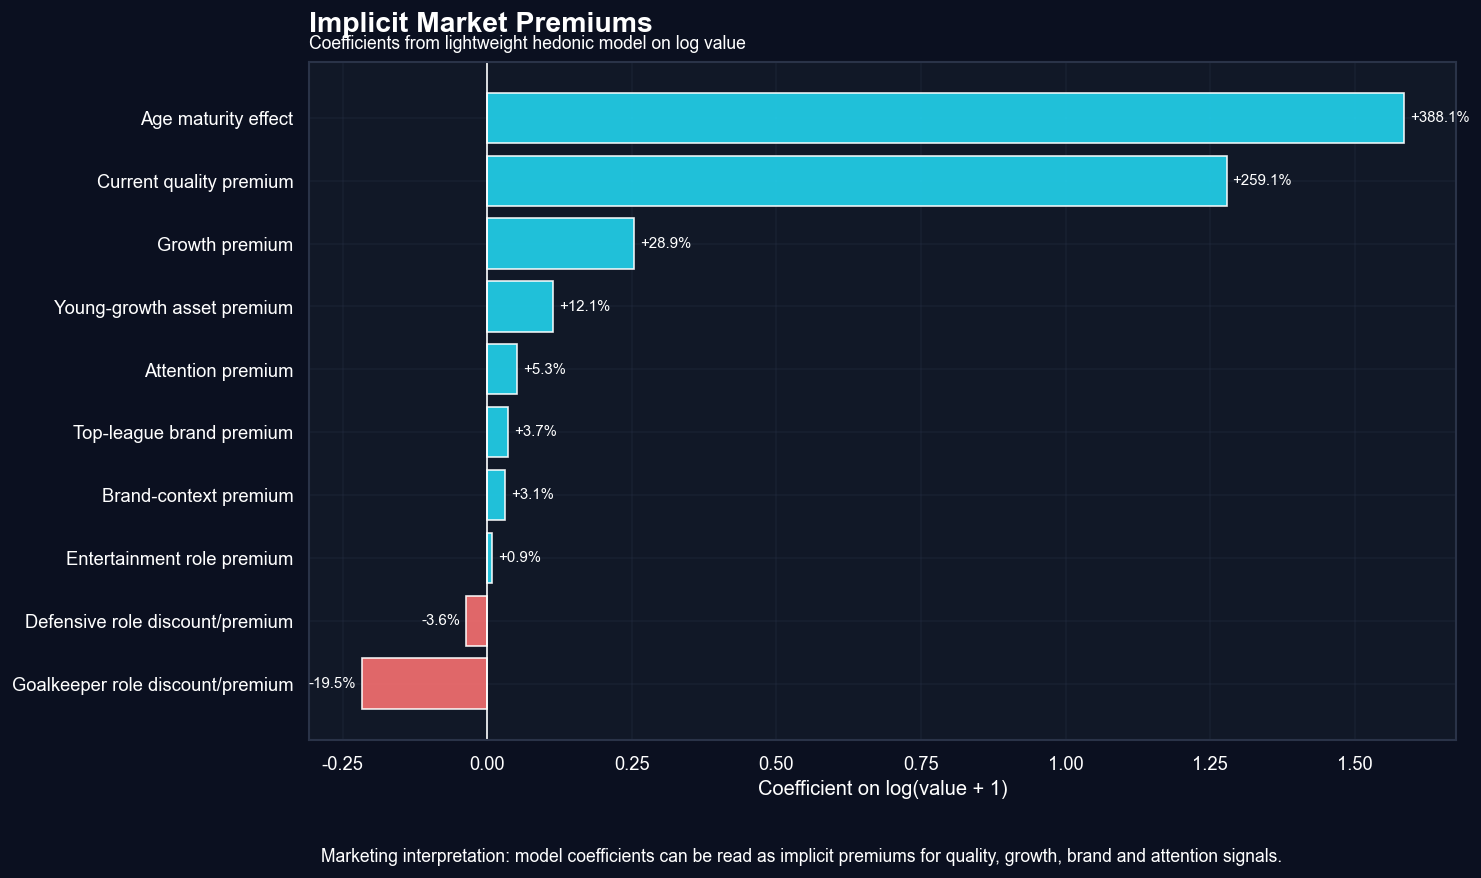

In [21]:
plot_coef = coef_table[~coef_table['variable'].isin(['age_sq'])].copy()
plot_coef = plot_coef.sort_values('coefficient')
colors = np.where(plot_coef['coefficient'].ge(0), CYAN, RED)

fig, ax = plt.subplots(figsize=(12.5, 7.5))
ax.barh(plot_coef['marketing_label'], plot_coef['coefficient'], color=colors, alpha=0.9)
ax.axvline(0, color=TEXT, linewidth=1)
style_axis(ax, 'Implicit Market Premiums', 'Coefficients from lightweight hedonic model on log value')
ax.set_xlabel('Coefficient on log(value + 1)')
for i, (_, r) in enumerate(plot_coef.iterrows()):
    ax.text(r['coefficient'] + (0.01 if r['coefficient'] >= 0 else -0.01), i, f"{r['premium_%']:+.1f}%", va='center', ha='left' if r['coefficient'] >= 0 else 'right', color=TEXT, fontsize=9)
add_slide_caption(ax, 'Marketing interpretation: model coefficients can be read as implicit premiums for quality, growth, brand and attention signals.')
plt.tight_layout()
savefig('11_hedonic_price_premiums.png')
plt.show()


### Pricing Model Interpretation

The model should be read like a marketing price decomposition:

- **Current quality premium**: higher overall rating commands a clear price uplift.
- **Growth premium**: potential gap and young-growth status represent option value.
- **Brand premium**: top leagues and stronger club contexts increase perceived market confidence.
- **Attention premium**: entertainment-oriented profiles receive visibility-driven valuation.

> **Slide takeaway:** Clubs reveal willingness to pay for quality, upside, brand context and attention, not for a single performance metric.


## 5. Competition and Differentiation

This section adds light differentiated-competition intuition without turning the notebook into formal IO theory.

Core idea:

- scarce young talents attract bidding pressure;
- leagues work like brand-differentiated markets;
- attacking stars occupy high-attention positions with stronger price signaling.

> **Slide takeaway:** Transfer spending shows competition for differentiated player assets.


In [22]:
# League transfer flow: Sankey if Plotly is available, heatmap fallback otherwise.
flow = transfers_clean.dropna(subset=['league_origin_club', 'league_new_club', 'cost']).copy()
top_flow_leagues = pd.concat([flow['league_origin_club'], flow['league_new_club']]).value_counts().head(12).index
flow_top = flow[flow['league_origin_club'].isin(top_flow_leagues) & flow['league_new_club'].isin(top_flow_leagues)]
flow_summary = flow_top.groupby(['league_origin_club', 'league_new_club']).agg(total_fee=('cost', 'sum'), deals=('name', 'count')).reset_index()
flow_summary = flow_summary.sort_values('total_fee', ascending=False).head(35)

if PLOTLY_AVAILABLE:
    labels = pd.Index(pd.concat([flow_summary['league_origin_club'], flow_summary['league_new_club']]).unique())
    label_to_id = {label: i for i, label in enumerate(labels)}
    sankey = go.Figure(data=[go.Sankey(
        node=dict(label=list(labels), pad=18, thickness=14, color='#1F2937'),
        link=dict(
            source=flow_summary['league_origin_club'].map(label_to_id),
            target=flow_summary['league_new_club'].map(label_to_id),
            value=flow_summary['total_fee'] / 1_000_000,
            color='rgba(34, 211, 238, 0.35)'
        )
    )])
    sankey.update_layout(
        title='League Transfer Flow: Brand-Differentiated Movement of Capital',
        paper_bgcolor=BG, plot_bgcolor=BG, font=dict(color=TEXT, size=11), height=650
    )
    sankey.show()
else:
    matrix = flow_top.pivot_table(index='league_origin_club', columns='league_new_club', values='cost', aggfunc='sum', fill_value=0) / 1_000_000
    matrix = matrix.loc[matrix.sum(axis=1).sort_values(ascending=False).head(10).index, matrix.sum(axis=0).sort_values(ascending=False).head(10).index]
    fig, ax = plt.subplots(figsize=(13, 8))
    sns.heatmap(matrix, cmap='magma', linewidths=.5, linecolor=GRID, ax=ax, cbar_kws={'label': 'Total transfer fee (€M)'})
    style_axis(ax, 'League Transfer Flow Heatmap', 'Capital flows across league-brand markets')
    ax.set_xlabel('Destination league')
    ax.set_ylabel('Origin league')
    plt.tight_layout()
    savefig('13_league_transfer_flow_heatmap.png')
    plt.show()

flow_summary.head(12)


,league_origin_club,league_new_club,total_fee,deals
70,Premier League,Premier League,604412000,24
89,Serie A,Serie A,266700000,30
7,Bundesliga,Premier League,266540000,15
35,LaLiga,Premier League,254050000,7
55,Ligue 1,Premier League,234850000,11
18,Eredivisie,Premier League,207370000,5
88,Serie A,Premier League,186000000,8
44,Liga Portugal,Premier League,180000000,5
53,Ligue 1,Ligue 1,156400000,17
0,Bundesliga,Bundesliga,135800000,26


Saved: charts/14_transfer_premium_heatmap.png


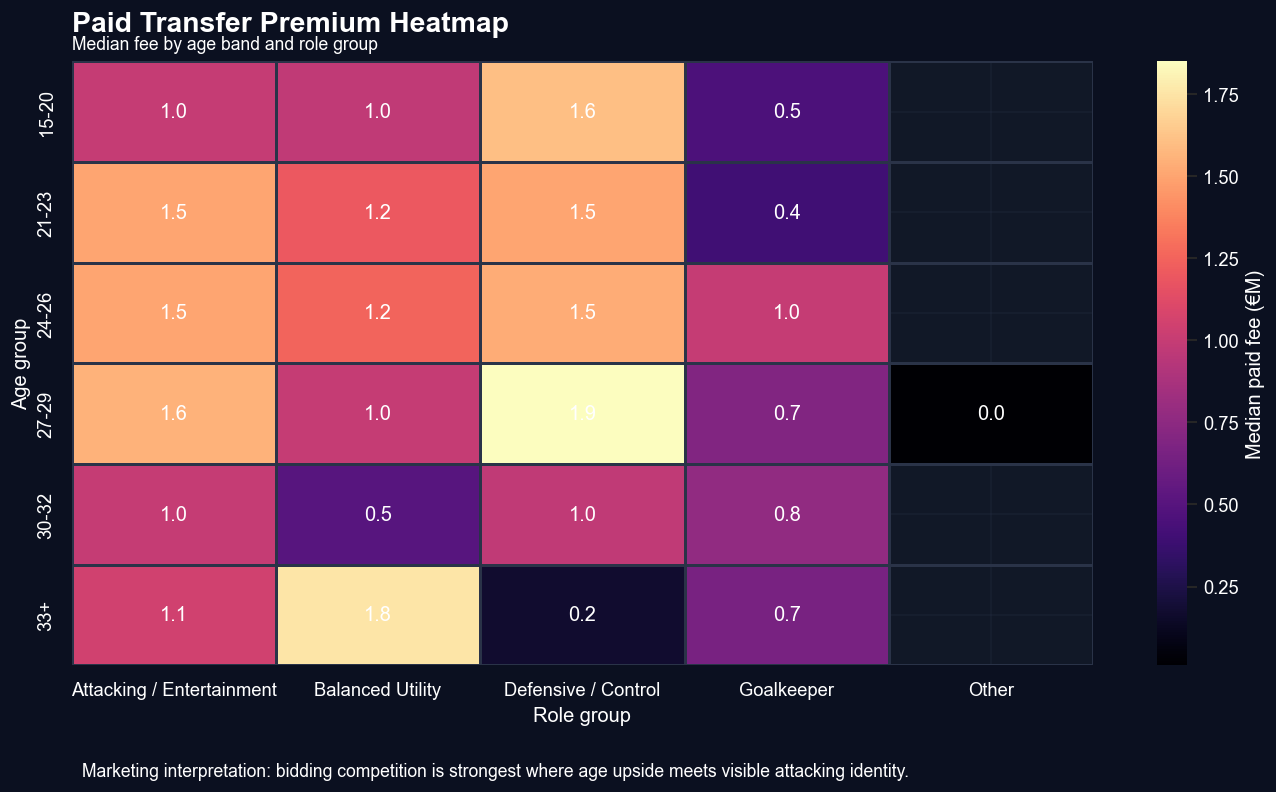

In [23]:
# Premium heatmap: age x role among paid transfers.
def transfer_role(pos):
    if pd.isna(pos):
        return 'Other'
    p = str(pos).upper()
    if any(k in p for k in ['FORWARD', 'LEFT WINGER', 'RIGHT WINGER', 'CENTRE-FORWARD', 'SECOND STRIKER']):
        return 'Attacking / Entertainment'
    if any(k in p for k in ['CENTRE-BACK', 'LEFT-BACK', 'RIGHT-BACK', 'DEFENDER']):
        return 'Defensive / Control'
    if 'GOALKEEPER' in p:
        return 'Goalkeeper'
    if any(k in p for k in ['MIDFIELD', 'MIDFIELDER']):
        return 'Balanced Utility'
    return 'Other'

transfers_clean['role_group'] = transfers_clean['position'].apply(transfer_role)
fee_heat = transfers_clean.pivot_table(index='age_group', columns='role_group', values='fee_million', aggfunc='median')

fig, ax = plt.subplots(figsize=(11.5, 6.8))
sns.heatmap(fee_heat, cmap='magma', annot=True, fmt='.1f', linewidths=.7, linecolor=GRID, ax=ax, cbar_kws={'label': 'Median paid fee (€M)'})
style_axis(ax, 'Paid Transfer Premium Heatmap', 'Median fee by age band and role group')
ax.set_xlabel('Role group')
ax.set_ylabel('Age group')
add_slide_caption(ax, 'Marketing interpretation: bidding competition is strongest where age upside meets visible attacking identity.')
plt.tight_layout()
savefig('14_transfer_premium_heatmap.png')
plt.show()


### Competition / Differentiation Interpretation

The competition story is intuitive rather than econometric:

- When a segment is scarce and attractive, clubs compete through higher willingness to pay.
- League flows show that leagues are not neutral containers; they are differentiated brand markets.
- Young attacking players combine upside, visibility and scarcity, making them especially premium-sensitive.

> **Slide takeaway:** Transfer markets behave like differentiated product markets where scarce identities attract stronger bidding.


## 6. Final Marketing Narrative

### Core Answer

Football clubs reveal market preferences through transfer spending by paying premiums for three kinds of positioning:

1. **Growth positioning**: young players with upside and resale optionality.
2. **Brand positioning**: players embedded in stronger league and club contexts.
3. **Attention positioning**: attacking, fast, technical and reputation-rich profiles.

### Presentation-Ready Takeaways

- **The market systematically rewards future upside.**
- **League identity functions similarly to brand equity.**
- **Entertainment-oriented player profiles receive disproportionate valuation.**
- **Transfer price is a strategic positioning signal, not merely a performance measure.**

### Suggested 10-Minute Presentation Flow

1. Start with the skewed price distribution: a star-driven premium market.
2. Show the three STP positioning maps: growth, brand, attention.
3. Use PCA/t-SNE to show latent player-product identities.
4. Present segmentation as a market portfolio.
5. Close with the hedonic premium chart: growth premium, brand premium, attention premium.

> **Final slide sentence:** Clubs do not simply buy football ability; they buy differentiated market positions under uncertainty.


## 7. Appendix: Marketing Interpretation, STP Export, and Gemini HTML Assets

This appended section preserves the existing notebook work and adds presentation infrastructure below the original analysis. It does three things:

1. Reviews the existing charts through marketing frameworks.
2. Adds a small number of STP-strengthening visualizations without replacing earlier charts.
3. Exports stable chart images and structured metadata for Gemini HTML generation.

> **Preservation note:** Existing charts, tables, markdown explanations and outputs are kept. The new files are exported under `outputs/charts/` with stable filenames.


In [24]:
from pathlib import Path
import shutil
import json

OUTPUT_DIR = Path('outputs')
OUTPUT_CHART_DIR = OUTPUT_DIR / 'charts'
OUTPUT_CHART_DIR.mkdir(parents=True, exist_ok=True)


def exportfig(path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    force_white_text()
    plt.savefig(path, dpi=220, bbox_inches='tight', facecolor=BG)
    print(f'Saved: {path}')

# Copy existing PNG assets into stable Gemini-ready filenames.
existing_chart_exports = [
    ('charts/01_data_understanding_dashboard.png', 'chart_01_data_understanding_dashboard.png'),
    ('charts/02_price_skewness.png', 'chart_02_price_skewness.png'),
    ('charts/03_youth_growth_positioning.png', 'chart_03_youth_growth_positioning.png'),
    ('charts/04_league_brand_ladder.png', 'chart_04_league_brand_ladder.png'),
    ('charts/05_attention_positioning.png', 'chart_05_attention_positioning.png'),
    ('charts/06_pca_price_gradient.png', 'chart_06_pca_price_gradient.png'),
    ('charts/07_pca_position_league.png', 'chart_07_pca_position_league.png'),
    ('charts/08_tsne_identity_maps.png', 'chart_08_tsne_identity_maps.png'),
    ('charts/09_positioning_maps.png', 'chart_09_positioning_maps.png'),
    ('charts/10_segmentation_market_segments.png', 'chart_10_segmentation_market_segments.png'),
    ('charts/11_hedonic_price_premiums.png', 'chart_11_hedonic_price_premiums.png'),
    ('charts/14_transfer_premium_heatmap.png', 'chart_12_transfer_premium_heatmap.png'),
]

copied = []
for src, dst in existing_chart_exports:
    src_path = Path(src)
    dst_path = OUTPUT_CHART_DIR / dst
    if src_path.exists():
        shutil.copy2(src_path, dst_path)
        copied.append(str(dst_path))
    else:
        print(f'Missing existing chart, not copied: {src_path}')

print(f'Copied {len(copied)} existing charts to {OUTPUT_CHART_DIR}')


Copied 12 existing charts to outputs/charts


### Task A: Existing Chart Review Through Marketing Frameworks

| Chart ID | Chart Title | Chart Type | Variables Used | Statistical Message | Marketing Model Link | Positioning Dimension | Keep Decision | Suggested Slide Section |
|---|---|---|---|---|---|---|---|---|
| chart_01 | Data Understanding Dashboard | Multi-panel bar dashboard | missingness, role group, league count | The database has enough coverage across role, league and price variables to support market segmentation. | STP segmentation and market research readiness | Overall STP foundation | keep_as_supporting | Method / Data credibility |
| chart_02 | Price Skewness | Histogram comparison | value_eur, log_value_eur | Transfer value is highly right-skewed; a small elite segment dominates market value. | 4P Price as premium signal; star economy | Overall price logic | core | Opening: Why price is marketing |
| chart_03 | Youth / Growth Positioning Map | Bubble scatter + trend | age, value, potential, growth_score | Young high-potential players occupy disproportionately high value zones. | STP targeting of growth assets; product lifecycle | Growth Positioning | core | Growth Premium |
| chart_04 | League / Brand Ladder | Horizontal bar chart | league_name, median value, top league | Top leagues form a clear price ladder. | Brand equity and quality signaling | Brand Positioning | core | Brand Premium |
| chart_05 | Entertainment / Attention Map | Scatter + density + regression guide | attention_score, log_value, overall | Entertainment-oriented player profiles show a positive price gradient. | Attention economy; Product + Promotion value | Attention Positioning | core | Attention Premium |
| chart_06 | PCA Price Gradient | PCA scatter | technical attributes, log value | High-value players concentrate in clearer latent archetype zones. | Perceptual mapping and differentiated products | Overall positioning | core | Player archetypes |
| chart_07 | PCA by Position and League | Two-panel PCA scatter | PCA components, position, league group | Position and league context structure the archetype map. | STP segmentation plus brand positioning | Brand / Positioning | supporting | Archetype proof |
| chart_08 | t-SNE Identity Maps | Four-panel embedding | player attributes, fee, age, league, role | Player identities form neighborhoods; price premiums appear in selected neighborhoods. | Consideration sets and differentiated competition | Overall STP / Attention | core | Market identity map |
| chart_09 | Marketing Positioning Maps | Four-panel positioning maps | potential, brand score, attention score, age, price | Growth, brand and attention each relate to price from different angles. | STP positioning maps and 4P Price | Integrated positioning | core | Strategy summary |
| chart_10 | Segmentation Market Segments | Bar + heatmap | cluster segment, value, age, overall, potential | Player profiles can be grouped into market segments with different price logic. | STP segmentation and targeting | Segmentation | core | Market segments |
| chart_11 | Implicit Market Premiums | Coefficient bar chart | hedonic model variables | Overall, growth, brand and attention signals translate into price premiums. | Hedonic pricing; revealed willingness to pay | Price / all premiums | core | Price model |
| chart_12 | Paid Transfer Premium Heatmap | Heatmap | transfer age group, role group, paid fee | Real paid fees vary by age-role combinations. | 4P Price as actual buying behavior | Growth + Attention | supporting | Validation / real transactions |
| prior_chart_12 | Scarcity Premium Map, if present in older copies | Bubble scatter | segment size, median value, attention, growth | Useful as competition intuition but less central to STP. | Light differentiated competition only | Not core | move_to_appendix / exclude_from_main_story | Backup only |

**Important story choice:** scarcity premium should not be a core insight because it moves the project toward economics / auction theory. The main story remains STP-based marketing positioning: growth, brand and attention premiums.


### Task A Completion: Slide Takeaways for Existing Charts

The existing chart review above uses the required fields: chart id, chart title, chart type, variables, statistical message, marketing model link, positioning dimension, keep decision and suggested slide section. The slide-ready takeaway sentences for the existing charts are:

| Chart ID | Slide Takeaway |
|---|---|
| chart_01 | The database is structured enough to support a genuine STP market analysis. |
| chart_02 | Transfer pricing behaves like a premium star market, not a normal uniform labor market. |
| chart_03 | The market prices future narratives, not just current performance. |
| chart_04 | League identity works like brand equity in player valuation. |
| chart_05 | Entertainment-oriented profiles receive attention premiums. |
| chart_06 | Clubs buy recognizable player archetypes, not isolated attributes. |
| chart_07 | Player role defines product category, while league context adds brand meaning. |
| chart_08 | The market prices identity neighborhoods, not only individual metrics. |
| chart_09 | Transfer fee is a combined signal of growth, brand and attention positioning. |
| chart_10 | Player segments sell different value propositions to different club strategies. |
| chart_11 | Quality, growth, brand and attention become implicit willingness-to-pay premiums. |
| chart_12 | Actual paid transfers validate that age-role positioning affects real buying behavior. |
| prior_chart_12_scarcity | If an older scarcity-premium chart is present, keep it out of the main story and move it to appendix. |


### Task C: Added STP-Strengthening Visualizations

The next charts are upgraded copies that strengthen the marketing narrative. They do not replace existing charts.

Added visual logic:

- **Growth Positioning:** compare age groups and log price distribution.
- **Brand Positioning:** compare role × league median value patterns.
- **Attention Positioning:** summarize segment archetypes in a radar chart.
- **Integrated STP Map:** plot growth score against attention score with price-sized bubbles.
- **Light Competition Support:** export a static league transfer-flow heatmap for Gemini, because the Plotly Sankey is interactive inside the notebook.


Saved: outputs/charts/chart_13_age_group_log_fee_violin.png


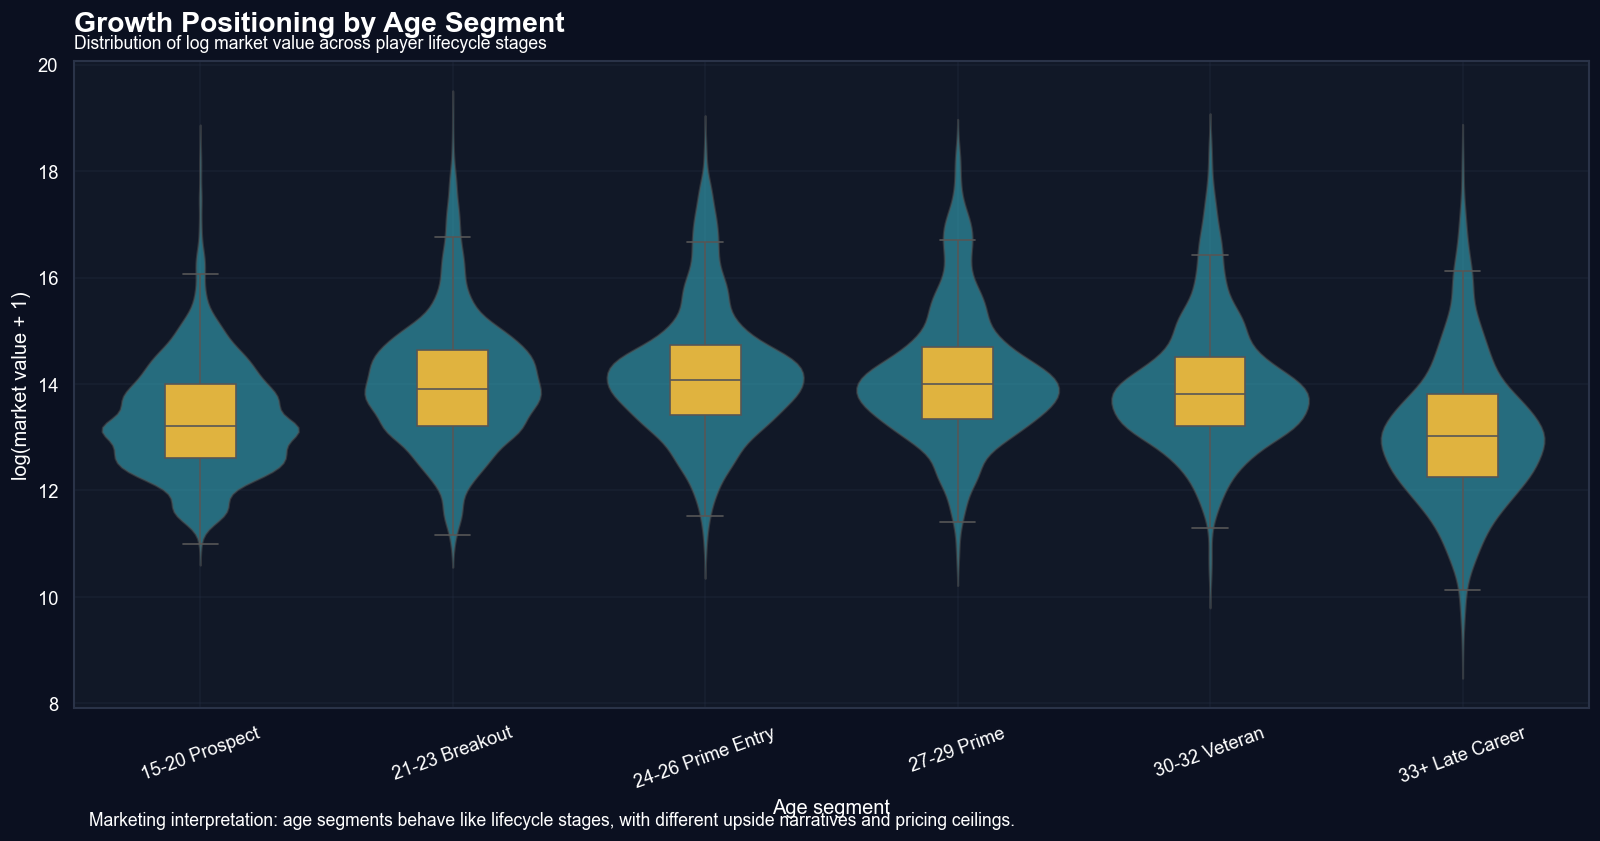

In [25]:
# New Chart 13: Growth positioning by age group.
growth_plot = players_clean.dropna(subset=['age_group', 'log_value_eur', 'value_million']).copy()
age_order = [x for x in ['15-20 Prospect', '21-23 Breakout', '24-26 Prime Entry', '27-29 Prime', '30-32 Veteran', '33+ Late Career'] if x in growth_plot['age_group'].astype(str).unique()]

fig, ax = plt.subplots(figsize=(13.5, 7.2))
sns.violinplot(
    data=growth_plot,
    x=growth_plot['age_group'].astype(str),
    y='log_value_eur',
    order=age_order,
    color=CYAN,
    inner=None,
    alpha=0.5,
    ax=ax
)
sns.boxplot(
    data=growth_plot,
    x=growth_plot['age_group'].astype(str),
    y='log_value_eur',
    order=age_order,
    width=0.28,
    color=GOLD,
    fliersize=0,
    ax=ax
)
style_axis(ax, 'Growth Positioning by Age Segment', 'Distribution of log market value across player lifecycle stages')
ax.set_xlabel('Age segment')
ax.set_ylabel('log(market value + 1)')
ax.tick_params(axis='x', rotation=20)
add_slide_caption(ax, 'Marketing interpretation: age segments behave like lifecycle stages, with different upside narratives and pricing ceilings.')
plt.tight_layout()
exportfig(OUTPUT_CHART_DIR / 'chart_13_age_group_log_fee_violin.png')
plt.show()


Saved: outputs/charts/chart_14_league_role_fee_heatmap.png


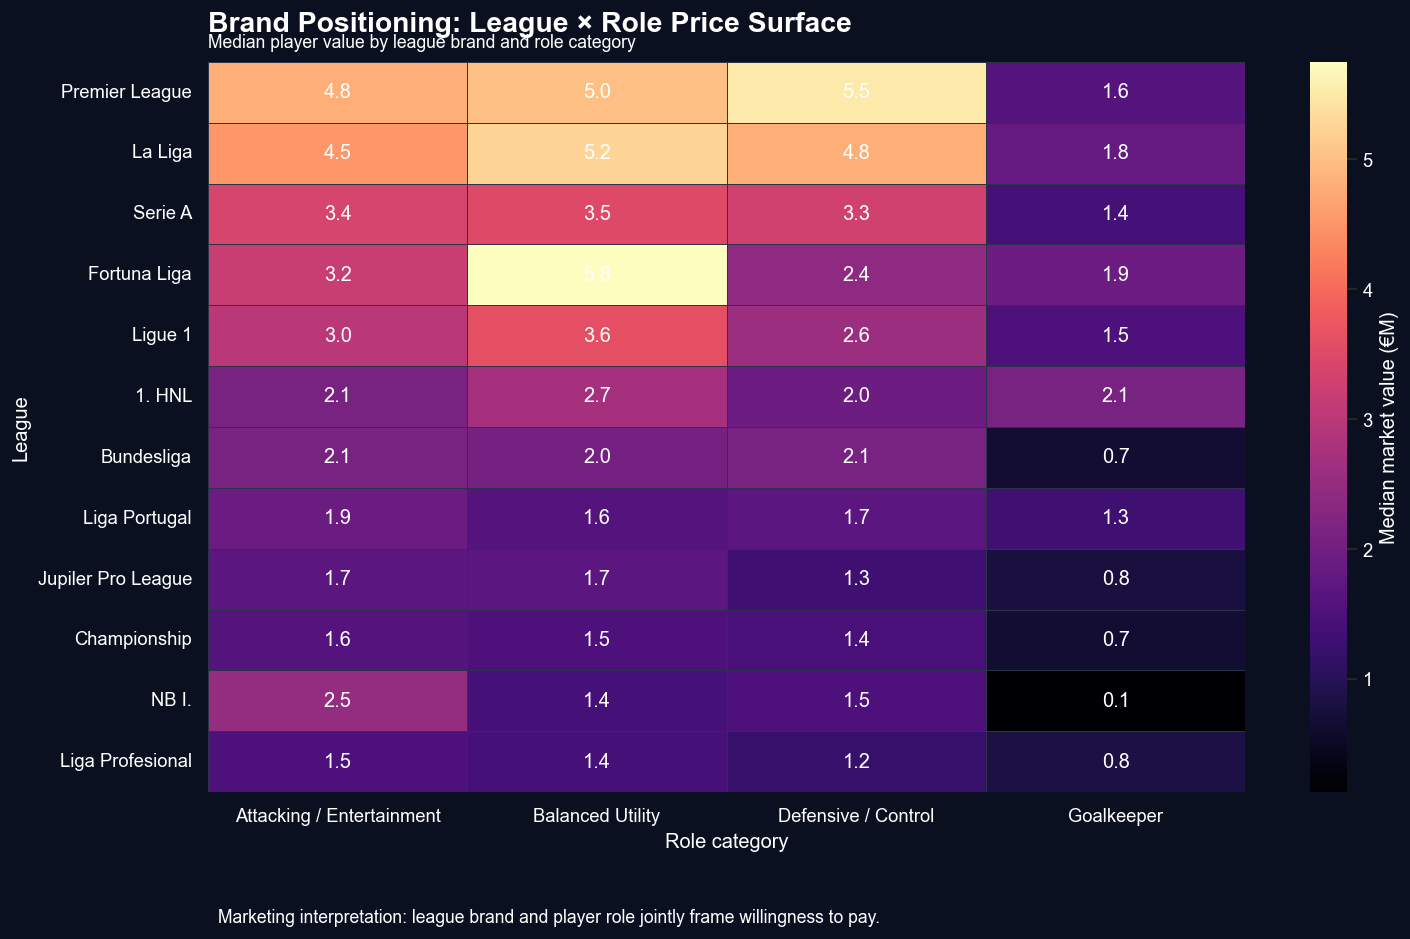

In [26]:
# New Chart 14: Brand positioning via league x role fee heatmap.
brand_base = players_clean.dropna(subset=['league_name', 'role_group', 'value_million']).copy()
top_brand_leagues = brand_base.groupby('league_name')['value_million'].median().sort_values(ascending=False).head(12).index
brand_heat = (
    brand_base[brand_base['league_name'].isin(top_brand_leagues)]
    .pivot_table(index='league_name', columns='role_group', values='value_million', aggfunc='median')
)
brand_heat = brand_heat.loc[brand_heat.median(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(12.8, 8))
sns.heatmap(
    brand_heat,
    cmap='magma',
    annot=True,
    fmt='.1f',
    linewidths=.6,
    linecolor=GRID,
    ax=ax,
    cbar_kws={'label': 'Median market value (€M)'}
)
style_axis(ax, 'Brand Positioning: League × Role Price Surface', 'Median player value by league brand and role category')
ax.set_xlabel('Role category')
ax.set_ylabel('League')
add_slide_caption(ax, 'Marketing interpretation: league brand and player role jointly frame willingness to pay.')
plt.tight_layout()
exportfig(OUTPUT_CHART_DIR / 'chart_14_league_role_fee_heatmap.png')
plt.show()


Saved: outputs/charts/chart_15_segment_archetype_radar.png


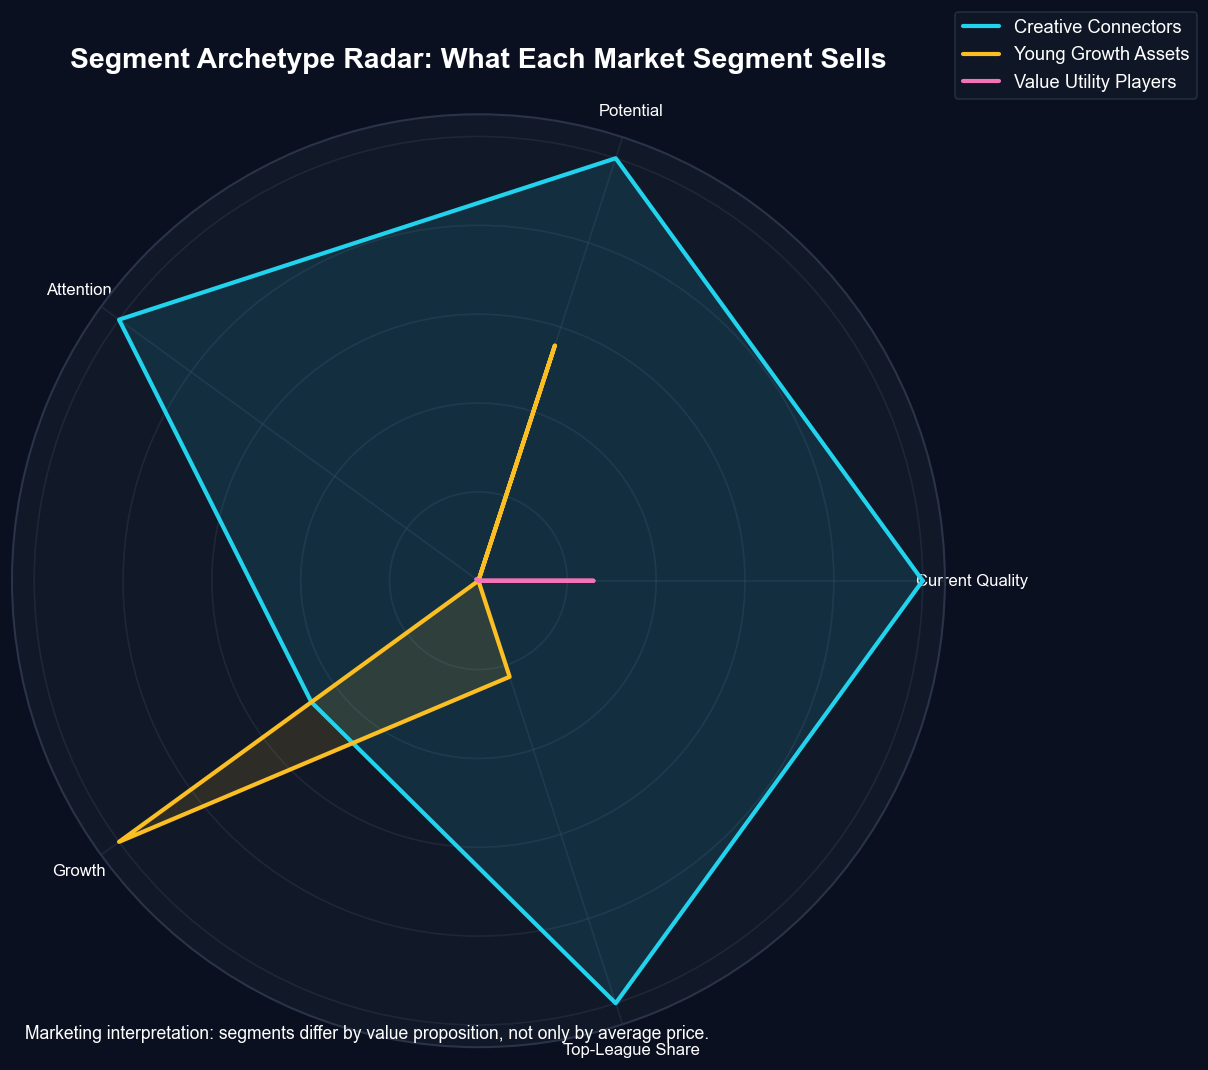

In [27]:
# New Chart 15: Segment archetype radar.
radar_source = segment_profile.copy()
radar_segments = radar_source.sort_values('median_value', ascending=False).head(4).index.tolist()
radar_cols = ['avg_overall', 'avg_potential', 'attention', 'growth', 'top_league_share']
radar_labels = ['Current Quality', 'Potential', 'Attention', 'Growth', 'Top-League Share']
radar_values = radar_source.loc[radar_segments, radar_cols].copy()
radar_values['top_league_share'] = radar_values['top_league_share'] * 100
radar_norm = radar_values.copy()
for c in radar_cols:
    mn, mx = radar_norm[c].min(), radar_norm[c].max()
    radar_norm[c] = 50 if mx == mn else (radar_norm[c] - mn) / (mx - mn) * 100

angles = np.linspace(0, 2 * np.pi, len(radar_cols), endpoint=False).tolist()
angles += angles[:1]

fig = plt.figure(figsize=(10.5, 9))
ax = plt.subplot(111, polar=True)
ax.set_facecolor(AX_BG)
colors = [CYAN, GOLD, PINK, GREEN]
for idx, seg in enumerate(radar_segments):
    vals = radar_norm.loc[seg, radar_cols].tolist()
    vals += vals[:1]
    ax.plot(angles, vals, color=colors[idx % len(colors)], linewidth=2.5, label=seg)
    ax.fill(angles, vals, color=colors[idx % len(colors)], alpha=0.12)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_labels, color=TEXT, fontsize=10)
ax.set_yticklabels([])
ax.grid(color=GRID, alpha=0.55)
ax.spines['polar'].set_color(GRID)
ax.set_title('Segment Archetype Radar: What Each Market Segment Sells', pad=28, color=TEXT, fontsize=17, fontweight='bold')
legend = ax.legend(loc='upper right', bbox_to_anchor=(1.28, 1.12), frameon=True)
for text in legend.get_texts():
    text.set_color(TEXT)
legend.get_frame().set_facecolor(AX_BG)
legend.get_frame().set_edgecolor(GRID)
fig.text(0.08, 0.04, 'Marketing interpretation: segments differ by value proposition, not only by average price.', color=TEXT, fontsize=10.5)
plt.tight_layout()
exportfig(OUTPUT_CHART_DIR / 'chart_15_segment_archetype_radar.png')
plt.show()


Saved: outputs/charts/chart_16_integrated_stp_positioning_map.png


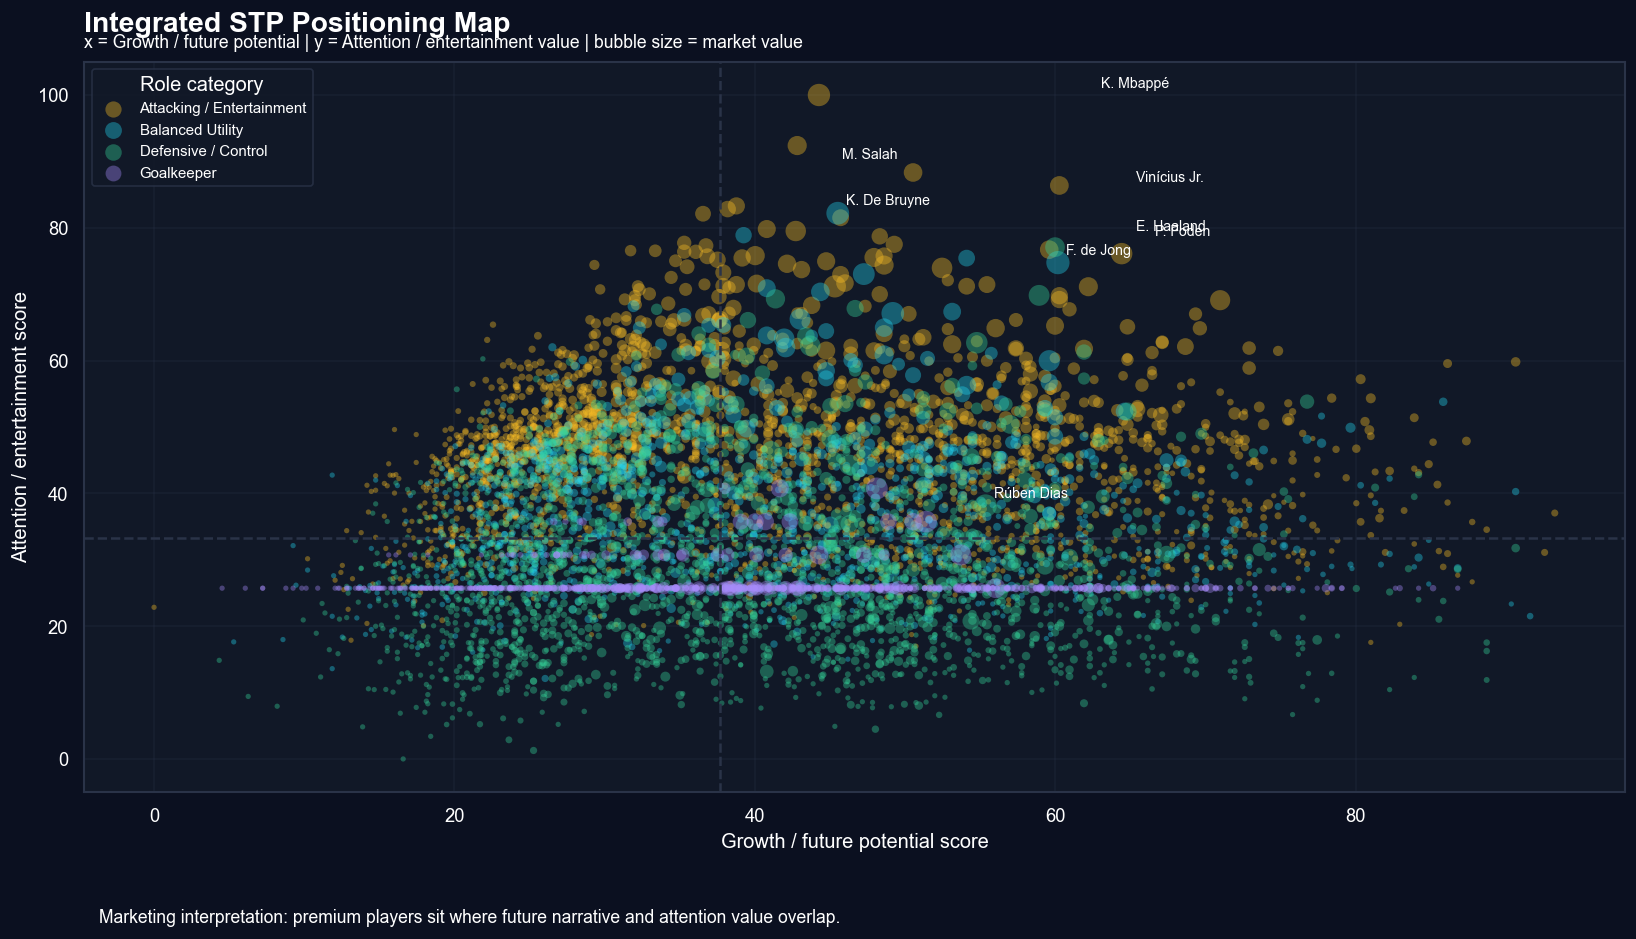

In [28]:
# New Chart 16: Integrated STP map.
stp_map = players_clean.dropna(subset=['growth_score', 'attention_score', 'value_million', 'role_group']).copy()
stp_map = stp_map.sample(min(6500, len(stp_map)), random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(13.8, 8))
role_palette = {
    'Attacking / Entertainment': GOLD,
    'Balanced Utility': CYAN,
    'Defensive / Control': GREEN,
    'Goalkeeper': PURPLE,
}
for role, data in stp_map.groupby('role_group'):
    ax.scatter(
        data['growth_score'],
        data['attention_score'],
        s=np.clip(np.sqrt(data['value_million'].clip(lower=0.1)) * 18, 10, 260),
        alpha=0.38,
        linewidths=0,
        color=role_palette.get(role, PINK),
        label=role
    )

elite = players_clean.nlargest(8, 'value_million')
for _, r in elite.iterrows():
    if pd.notna(r['growth_score']) and pd.notna(r['attention_score']):
        ax.annotate(r['short_name'], (r['growth_score'], r['attention_score']), xytext=(5, 5), textcoords='offset points', fontsize=8.5, color=TEXT)

ax.axvline(players_clean['growth_score'].median(), color=GRID, linewidth=1.5, linestyle='--')
ax.axhline(players_clean['attention_score'].median(), color=GRID, linewidth=1.5, linestyle='--')
style_axis(ax, 'Integrated STP Positioning Map', 'x = Growth / future potential | y = Attention / entertainment value | bubble size = market value')
ax.set_xlabel('Growth / future potential score')
ax.set_ylabel('Attention / entertainment score')
ax.legend(loc='upper left', fontsize=9, title='Role category')
add_slide_caption(ax, 'Marketing interpretation: premium players sit where future narrative and attention value overlap.')
plt.tight_layout()
exportfig(OUTPUT_CHART_DIR / 'chart_16_integrated_stp_positioning_map.png')
plt.show()


Saved: outputs/charts/chart_17_league_transfer_flow_heatmap.png


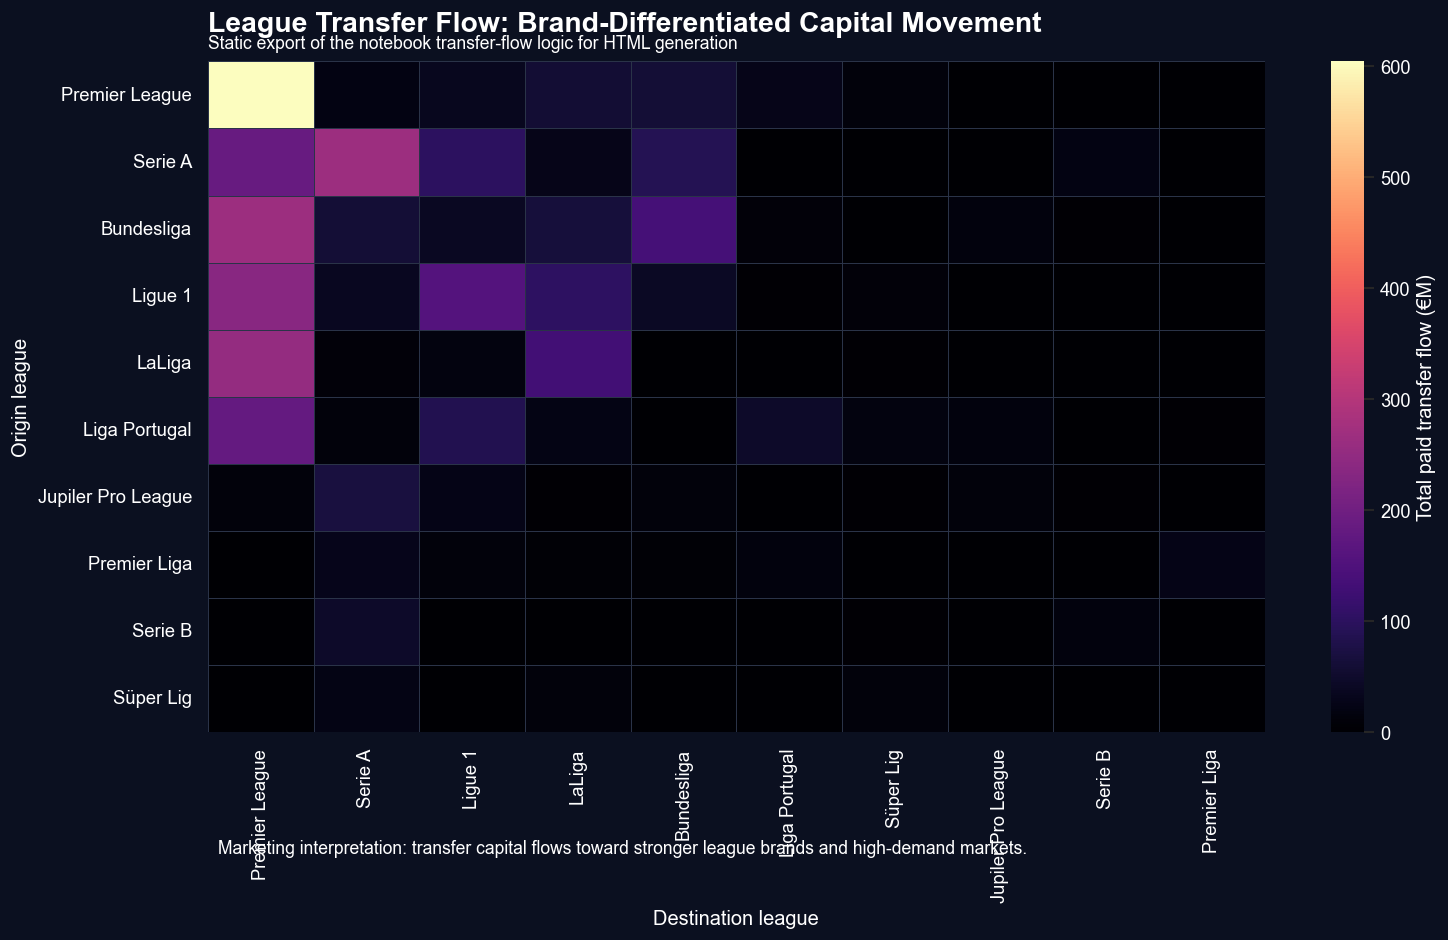

In [29]:
# Supporting export: static league transfer flow heatmap for Gemini HTML.
flow = transfers_clean.dropna(subset=['league_origin_club', 'league_new_club', 'cost']).copy()
top_flow_leagues = pd.concat([flow['league_origin_club'], flow['league_new_club']]).value_counts().head(10).index
flow_top = flow[flow['league_origin_club'].isin(top_flow_leagues) & flow['league_new_club'].isin(top_flow_leagues)]
flow_matrix = flow_top.pivot_table(index='league_origin_club', columns='league_new_club', values='cost', aggfunc='sum', fill_value=0) / 1_000_000
flow_matrix = flow_matrix.loc[flow_matrix.sum(axis=1).sort_values(ascending=False).index, flow_matrix.sum(axis=0).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(13, 8))
sns.heatmap(flow_matrix, cmap='magma', linewidths=.5, linecolor=GRID, ax=ax, cbar_kws={'label': 'Total paid transfer flow (€M)'})
style_axis(ax, 'League Transfer Flow: Brand-Differentiated Capital Movement', 'Static export of the notebook transfer-flow logic for HTML generation')
ax.set_xlabel('Destination league')
ax.set_ylabel('Origin league')
add_slide_caption(ax, 'Marketing interpretation: transfer capital flows toward stronger league brands and high-demand markets.')
plt.tight_layout()
exportfig(OUTPUT_CHART_DIR / 'chart_17_league_transfer_flow_heatmap.png')
plt.show()


In [30]:
# Task B: Gemini-ready JSON metadata.
charts_metadata = [
    {
        'chart_id': 'chart_01',
        'title': 'Data Understanding Dashboard',
        'chart_type': 'multi-panel bar dashboard',
        'image_path': 'outputs/charts/chart_01_data_understanding_dashboard.png',
        'variables': ['missingness', 'role_group', 'league_name'],
        'main_insight': 'The database has enough role, league, ability and price coverage to support STP-based market analysis.',
        'marketing_interpretation': 'This chart establishes the market research foundation: players can be segmented by role, league context and valuation variables.',
        'framework_tags': ['STP', 'Segmentation', 'Market Research'],
        'recommended_slide': 'Method and data credibility',
        'priority': 'supporting',
        'speaker_note': 'Use this briefly to prove that the analysis is not anecdotal; it has enough structured variables for marketing interpretation.'
    },
    {
        'chart_id': 'chart_02',
        'title': 'Price Skewness: Star-Driven Premium Market',
        'chart_type': 'histogram comparison',
        'image_path': 'outputs/charts/chart_02_price_skewness.png',
        'variables': ['value_eur', 'log_value_eur'],
        'main_insight': 'Football transfer value is extremely right-skewed, with a small elite segment dominating total market value.',
        'marketing_interpretation': 'The market behaves like a premium star economy where symbolic value, scarcity and attention concentrate price at the top.',
        'framework_tags': ['Price', '4P', 'Premium Pricing'],
        'recommended_slide': 'Opening: why transfer price is a marketing question',
        'priority': 'core',
        'speaker_note': 'This is the hook: transfer pricing looks like a premium product market, not a normal uniform labor market.'
    },
    {
        'chart_id': 'chart_03',
        'title': 'Youth / Growth Positioning Map',
        'chart_type': 'bubble scatter with smooth trend',
        'image_path': 'outputs/charts/chart_03_youth_growth_positioning.png',
        'variables': ['age', 'value_million', 'potential', 'growth_score'],
        'main_insight': 'Young high-potential players occupy disproportionate high-value zones.',
        'marketing_interpretation': 'Clubs position these players as future-growth assets rather than merely current-performance players.',
        'framework_tags': ['STP', 'Targeting', 'Growth Positioning', 'Price'],
        'recommended_slide': 'Growth Positioning: youth and future value',
        'priority': 'core',
        'speaker_note': 'Explain that the club is buying an option on future value, resale value and brand story.'
    },
    {
        'chart_id': 'chart_04',
        'title': 'League / Brand Positioning: Median Price Ladder',
        'chart_type': 'horizontal bar chart',
        'image_path': 'outputs/charts/chart_04_league_brand_ladder.png',
        'variables': ['league_name', 'median_value', 'top_league'],
        'main_insight': 'Top leagues form a visible market-value ladder.',
        'marketing_interpretation': 'League identity acts like a brand label that signals quality, reduces uncertainty and frames willingness to pay.',
        'framework_tags': ['STP', 'Brand Positioning', 'Brand Equity', 'Price'],
        'recommended_slide': 'Brand Positioning: league identity and brand equity',
        'priority': 'core',
        'speaker_note': 'Use this to translate league differences into brand equity rather than only football strength.'
    },
    {
        'chart_id': 'chart_05',
        'title': 'Entertainment / Attention Positioning Map',
        'chart_type': 'scatter with density contour and trend line',
        'image_path': 'outputs/charts/chart_05_attention_positioning.png',
        'variables': ['attention_score', 'log_value_eur', 'overall'],
        'main_insight': 'Entertainment-oriented player profiles show a positive price gradient.',
        'marketing_interpretation': 'Attacking spectacle, dribbling, speed and reputation turn players into attention-generating assets.',
        'framework_tags': ['STP', 'Attention Positioning', 'Promotion', 'Price'],
        'recommended_slide': 'Attention Positioning: entertainment and visibility premium',
        'priority': 'core',
        'speaker_note': 'Connect football highlights to attention economy: the player is both product and promotional asset.'
    },
    {
        'chart_id': 'chart_06',
        'title': 'PCA Archetype Map: Price Gradient',
        'chart_type': 'PCA scatter',
        'image_path': 'outputs/charts/chart_06_pca_price_gradient.png',
        'variables': ['technical_attributes', 'PC1', 'PC2', 'log_value_eur'],
        'main_insight': 'High-value players concentrate in clearer latent archetype regions.',
        'marketing_interpretation': 'The market buys recognizable player archetypes, not isolated individual attributes.',
        'framework_tags': ['Positioning', 'Perceptual Map', 'Differentiation'],
        'recommended_slide': 'Player archetypes and positioning',
        'priority': 'core',
        'speaker_note': 'Frame PCA as a marketing perceptual map: it shows where player-products sit in the market mind.'
    },
    {
        'chart_id': 'chart_07',
        'title': 'PCA Archetypes by Position and League Brand',
        'chart_type': 'two-panel PCA scatter',
        'image_path': 'outputs/charts/chart_07_pca_position_league.png',
        'variables': ['PC1', 'PC2', 'position_category', 'top_league_label'],
        'main_insight': 'Position and league context structure the archetype map.',
        'marketing_interpretation': 'Player role defines product category, while league context adds brand meaning.',
        'framework_tags': ['STP', 'Segmentation', 'Brand Positioning'],
        'recommended_slide': 'Supporting archetype evidence',
        'priority': 'supporting',
        'speaker_note': 'Use if time allows after the PCA price map; it explains why position and league are not just controls.'
    },
    {
        'chart_id': 'chart_08',
        'title': 't-SNE Identity Maps',
        'chart_type': 'four-panel t-SNE embedding',
        'image_path': 'outputs/charts/chart_08_tsne_identity_maps.png',
        'variables': ['player_attributes', 'log_value_eur', 'age_group', 'league_group', 'role_group'],
        'main_insight': 'Player identities cluster into neighborhoods, and price premiums appear in selected neighborhoods.',
        'marketing_interpretation': 'Clubs compare players within identity-based consideration sets, not across the entire market at once.',
        'framework_tags': ['STP', 'Positioning', 'Consideration Set', 'Differentiated Competition'],
        'recommended_slide': 'How the market organizes player identities',
        'priority': 'core',
        'speaker_note': 'This is the visual proof that the market has neighborhoods of substitutable but differentiated products.'
    },
    {
        'chart_id': 'chart_09',
        'title': 'Marketing Positioning Maps',
        'chart_type': 'four-panel positioning map',
        'image_path': 'outputs/charts/chart_09_positioning_maps.png',
        'variables': ['potential', 'brand_score', 'attention_score', 'age', 'log_value_eur'],
        'main_insight': 'Growth, brand and attention each show a relationship with price from different angles.',
        'marketing_interpretation': 'This is the integrated STP view: clubs price multiple positioning dimensions simultaneously.',
        'framework_tags': ['STP', 'Positioning', 'Price', 'Growth Positioning', 'Brand Positioning', 'Attention Positioning'],
        'recommended_slide': 'Integrated positioning summary',
        'priority': 'core',
        'speaker_note': 'Use this as the strategic summary chart before moving to segmentation and price model.'
    },
    {
        'chart_id': 'chart_10',
        'title': 'Segmentation: Market Segments and Segment DNA',
        'chart_type': 'bar chart plus heatmap',
        'image_path': 'outputs/charts/chart_10_segmentation_market_segments.png',
        'variables': ['market_segment', 'median_value', 'age', 'overall', 'potential', 'attention', 'growth'],
        'main_insight': 'Player profiles can be grouped into meaningful market segments with different price logic.',
        'marketing_interpretation': 'This operationalizes STP segmentation by naming player groups as market categories rather than just football roles.',
        'framework_tags': ['STP', 'Segmentation', 'Targeting'],
        'recommended_slide': 'Market segments',
        'priority': 'core',
        'speaker_note': 'Translate each segment into a value proposition: growth asset, creative connector, utility value.'
    },
    {
        'chart_id': 'chart_11',
        'title': 'Implicit Market Premiums',
        'chart_type': 'coefficient bar chart',
        'image_path': 'outputs/charts/chart_11_hedonic_price_premiums.png',
        'variables': ['age', 'overall', 'potential_gap', 'attention_score', 'club_brand_score', 'top_league'],
        'main_insight': 'Quality, growth, brand and attention signals translate into measurable price premiums.',
        'marketing_interpretation': 'The model converts positioning narratives into revealed willingness-to-pay language.',
        'framework_tags': ['Price', '4P', 'Growth Premium', 'Brand Premium', 'Attention Premium'],
        'recommended_slide': 'Transfer fee as revealed willingness to pay',
        'priority': 'core',
        'speaker_note': 'Do not present this as prediction accuracy; present it as a premium decomposition.'
    },
    {
        'chart_id': 'chart_12',
        'title': 'Paid Transfer Premium Heatmap',
        'chart_type': 'heatmap',
        'image_path': 'outputs/charts/chart_12_transfer_premium_heatmap.png',
        'variables': ['transfer_age_group', 'role_group', 'paid_transfer_fee'],
        'main_insight': 'Actual paid fees vary across age-role combinations.',
        'marketing_interpretation': 'This validates that positioning logic appears in observed buying behavior, not only estimated market value.',
        'framework_tags': ['Price', 'Revealed Preference', 'Growth Positioning', 'Attention Positioning'],
        'recommended_slide': 'Validation using real transactions',
        'priority': 'supporting',
        'speaker_note': 'Use near the end to show that the argument is grounded in actual paid transfer fees.'
    },
    {
        'chart_id': 'chart_13',
        'title': 'Growth Positioning by Age Segment',
        'chart_type': 'violin plus box plot',
        'image_path': 'outputs/charts/chart_13_age_group_log_fee_violin.png',
        'variables': ['age_group', 'log_value_eur'],
        'main_insight': 'Age lifecycle segments have different price distributions and upside ceilings.',
        'marketing_interpretation': 'This clarifies youth as a lifecycle positioning variable rather than a simple age effect.',
        'framework_tags': ['STP', 'Growth Positioning', 'Product Lifecycle'],
        'recommended_slide': 'Growth Positioning detail',
        'priority': 'supporting',
        'speaker_note': 'Use this if the audience needs a clearer distribution view after the bubble map.'
    },
    {
        'chart_id': 'chart_14',
        'title': 'Brand Positioning: League × Role Price Surface',
        'chart_type': 'heatmap',
        'image_path': 'outputs/charts/chart_14_league_role_fee_heatmap.png',
        'variables': ['league_name', 'role_group', 'median_value_million'],
        'main_insight': 'League brand and player role jointly shape median valuation.',
        'marketing_interpretation': 'Brand premium is not uniform; it interacts with player product category.',
        'framework_tags': ['STP', 'Brand Positioning', 'Segmentation'],
        'recommended_slide': 'Brand Positioning detail',
        'priority': 'supporting',
        'speaker_note': 'Use as a stronger version of league-brand interpretation when discussing role differences.'
    },
    {
        'chart_id': 'chart_15',
        'title': 'Segment Archetype Radar',
        'chart_type': 'radar chart',
        'image_path': 'outputs/charts/chart_15_segment_archetype_radar.png',
        'variables': ['market_segment', 'overall', 'potential', 'attention', 'growth', 'top_league_share'],
        'main_insight': 'Market segments differ by value proposition, not only by price.',
        'marketing_interpretation': 'Each segment sells a different bundle of benefits: quality, upside, attention or brand access.',
        'framework_tags': ['STP', 'Segmentation', 'Positioning'],
        'recommended_slide': 'Segment value propositions',
        'priority': 'supporting',
        'speaker_note': 'This chart helps convert clustering into marketing language.'
    },
    {
        'chart_id': 'chart_16',
        'title': 'Integrated STP Positioning Map',
        'chart_type': 'bubble scatter',
        'image_path': 'outputs/charts/chart_16_integrated_stp_positioning_map.png',
        'variables': ['growth_score', 'attention_score', 'value_million', 'role_group'],
        'main_insight': 'Premium players often sit where future potential and attention value overlap.',
        'marketing_interpretation': 'This is the clearest consulting-style map of growth positioning versus attention positioning.',
        'framework_tags': ['STP', 'Growth Positioning', 'Attention Positioning', 'Price'],
        'recommended_slide': 'Integrated STP map',
        'priority': 'core',
        'speaker_note': 'Use this as a final visual synthesis before the conclusion.'
    },
    {
        'chart_id': 'chart_17',
        'title': 'League Transfer Flow Heatmap',
        'chart_type': 'flow heatmap',
        'image_path': 'outputs/charts/chart_17_league_transfer_flow_heatmap.png',
        'variables': ['origin_league', 'destination_league', 'total_paid_fee'],
        'main_insight': 'Transfer capital flows toward stronger league brands and high-demand markets.',
        'marketing_interpretation': 'This provides light differentiated-competition intuition without making scarcity the core story.',
        'framework_tags': ['Brand Positioning', 'Differentiated Competition', 'Price'],
        'recommended_slide': 'Light competition intuition',
        'priority': 'appendix',
        'speaker_note': 'Keep this as optional support; avoid turning the project into auction theory.'
    },
]

presentation_outline = [
    {'slide_title': 'Why transfer price is a marketing question', 'objective': 'Open with price as revealed preference.', 'chart_to_use': ['chart_02'], 'marketing_framework': '4P Price', 'key_message': 'Transfer fees reveal what clubs value.', 'speaker_note': 'Start from the skewed market to show that this is a premium positioning market.'},
    {'slide_title': 'Course framework mapping: 5C to STP to Price', 'objective': 'Anchor the project in marketing models.', 'chart_to_use': ['chart_01'], 'marketing_framework': '5C + STP + 4P', 'key_message': 'Players, clubs and leagues form a structured market system.', 'speaker_note': 'Keep this concise; the main model is STP.'},
    {'slide_title': 'Growth Positioning', 'objective': 'Show youth and potential as future-value positioning.', 'chart_to_use': ['chart_03', 'chart_13'], 'marketing_framework': 'STP + Product Lifecycle', 'key_message': 'The market prices future narratives, not just current performance.', 'speaker_note': 'Use chart_03 as the main visual; chart_13 is backup detail.'},
    {'slide_title': 'Brand Positioning', 'objective': 'Show league identity as brand equity.', 'chart_to_use': ['chart_04', 'chart_14'], 'marketing_framework': 'Brand Equity + STP Positioning', 'key_message': 'League identity functions like a quality label.', 'speaker_note': 'Translate league effects into brand and risk-reduction language.'},
    {'slide_title': 'Attention Positioning', 'objective': 'Show entertainment value as marketable attention.', 'chart_to_use': ['chart_05'], 'marketing_framework': 'Attention Economy + 4P Promotion', 'key_message': 'Entertainment-oriented players receive attention premiums.', 'speaker_note': 'Explain that attacking stars are both on-field products and media assets.'},
    {'slide_title': 'Player archetypes and identity neighborhoods', 'objective': 'Move beyond descriptive stats into multivariate identity.', 'chart_to_use': ['chart_06', 'chart_08'], 'marketing_framework': 'Perceptual Map + Consideration Set', 'key_message': 'The market prices recognizable player identities.', 'speaker_note': 'Use PCA first, then t-SNE if time allows.'},
    {'slide_title': 'Segmentation and targeting', 'objective': 'Name player groups as market segments.', 'chart_to_use': ['chart_10', 'chart_15'], 'marketing_framework': 'STP Segmentation and Targeting', 'key_message': 'Different player segments sell different value propositions.', 'speaker_note': 'Connect clusters to club strategy and budget constraints.'},
    {'slide_title': 'Price premium decomposition', 'objective': 'Connect the narrative to revealed willingness to pay.', 'chart_to_use': ['chart_11'], 'marketing_framework': '4P Price + Hedonic Pricing', 'key_message': 'Quality, growth, brand and attention become implicit premiums.', 'speaker_note': 'Avoid formal econometrics; focus on premium interpretation.'},
    {'slide_title': 'Integrated STP map', 'objective': 'Provide one consulting-style summary visual.', 'chart_to_use': ['chart_16'], 'marketing_framework': 'STP Positioning', 'key_message': 'Premium players combine future potential and attention value.', 'speaker_note': 'This is the strongest final visual before conclusion.'},
    {'slide_title': 'Validation and light competition intuition', 'objective': 'Use actual transactions and flows as support.', 'chart_to_use': ['chart_12', 'chart_17'], 'marketing_framework': 'Revealed Preference + Differentiated Competition', 'key_message': 'Actual payments and capital flows support the positioning story.', 'speaker_note': 'Keep this secondary. Do not center scarcity premium.'},
    {'slide_title': 'Conclusion', 'objective': 'Close the argument.', 'chart_to_use': ['chart_09'], 'marketing_framework': 'STP + 4P Price', 'key_message': 'Transfer fee is the price of positioning under uncertainty.', 'speaker_note': 'End with growth, brand and attention as the three premiums.'},
]

project_json = {
    'project_title': 'How Football Clubs Reveal Market Preferences Through Transfer Spending',
    'core_framework': {
        'main_model': 'STP',
        'price_role': 'Transfer fee as revealed willingness to pay',
        'positioning_dimensions': [
            'Growth Positioning',
            'Brand Positioning',
            'Attention Positioning'
        ]
    },
    'charts': charts_metadata,
    'presentation_outline': presentation_outline,
    'excluded_from_main_story': [
        {
            'chart_id': 'prior_chart_12_scarcity_premium',
            'reason': 'Scarcity premium is useful only as light differentiated-competition intuition. It should not be a core insight because it shifts the project toward economics / auction theory rather than STP-based marketing positioning.',
            'recommended_action': 'move_to_appendix_or_exclude_from_main_story'
        }
    ]
}

json_path = Path('football_marketing_charts.json')
json_path.write_text(json.dumps(project_json, ensure_ascii=False, indent=2), encoding='utf-8')
print(f'Wrote {json_path.resolve()} with {len(charts_metadata)} chart records')


Wrote /Users/apple/hajime/football_transfer_analysis/football_marketing_charts.json with 17 chart records


### Task D: Interpretation Format for Major Charts

Use this four-part interpretation structure in the presentation:

1. **Statistical interpretation:** what the chart empirically shows.
2. **STP interpretation:** how it supports segmentation, targeting or positioning.
3. **Price interpretation:** how transfer fee reveals willingness to pay.
4. **Slide-ready sentence:** one concise statement for the HTML slide.

Example for Growth Positioning:

- **Statistical interpretation:** younger high-potential players occupy higher valuation zones.
- **STP interpretation:** the market segments them as growth assets rather than only current-performance players.
- **Price interpretation:** transfer fee reflects future expected value, resale potential and brand-building optionality.
- **Slide-ready sentence:** The market prices future narratives, not just current performance.


### Final Summary Cell: What Was Added and How to Use the Charts

**Added in this appended section:**

- Stable Gemini-ready image exports under `outputs/charts/`.
- New STP-strengthening charts:
  - `chart_13_age_group_log_fee_violin.png`
  - `chart_14_league_role_fee_heatmap.png`
  - `chart_15_segment_archetype_radar.png`
  - `chart_16_integrated_stp_positioning_map.png`
  - `chart_17_league_transfer_flow_heatmap.png`
- Structured chart metadata exported to `football_marketing_charts.json`.
- A presentation outline proposal exported separately to `football_marketing_outline_proposal.md`.

**Core charts for the main story:**

- `chart_02`: price skewness and star-driven premium market.
- `chart_03`: Growth Positioning.
- `chart_04`: Brand Positioning.
- `chart_05`: Attention Positioning.
- `chart_06` and `chart_08`: multivariate player archetypes and identity neighborhoods.
- `chart_10`: STP segmentation.
- `chart_11`: price premium decomposition.
- `chart_16`: integrated STP positioning map.

**Supporting charts:**

- `chart_01`, `chart_07`, `chart_12`, `chart_13`, `chart_14`, `chart_15`.

**Appendix / optional chart:**

- `chart_17` league transfer-flow heatmap can support light differentiated competition intuition.

**Exclude from main story:**

- Any scarcity-premium chart, especially an older `chart_12` scarcity-premium version if present in prior copies. It should be moved to appendix or excluded because scarcity premium shifts the project toward economics / auction theory. The main marketing story should remain STP-based: **Growth Premium, Brand Premium, and Attention Premium**.
